# KMOS — Sample Statistics

Statistical overview of the stacked KMOS sample.

**Sections**
1. Configuration, helpers, catalog, load, stack, annuli (from `kmos_snr_annuli.ipynb`)
2. Sample preparation — **one row per galaxy** (survey region, target id) with detection flags
3. Sample overview — counts by field / band / z-type, detection rates
4. SNR histograms — per emission line
5. Detection rates — by field and band
6. SNR vs. redshift scatter
7. SNR by field — violin plots
8. Mean SNR radial profiles — whole sample + by field
9. Exposure time vs. SNR
10. Redshift distributions


In [1]:
import glob, os, csv, pathlib, warnings, re
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from astropy.io import fits

# ── DATA SOURCE SWITCH ────────────────────────────────────────────────────────
USE_EXTERNAL = True           # True  → use kmos_proc_and_comb_server/ (combined cubes)
                              # False → use kmos_ob_proc_server/        (own reduced files)
COMB_BASE    = "kmos_proc_and_comb_server"

# ── paths ──────────────────────────────────────────────────────────────────────
BASE         = "kmos_ob_proc_server"
SUFFIX       = "_s_i_bkg2d_rv.fits"
ECDFS_TABLE  = pathlib.Path("scripts") / "table_ifus_ECDFS 2.fits"
COSMOS_TABLE = pathlib.Path("scripts") / "table_ifus_COSMOS_Field_exptime.fits"

# ── extraction parameters ──────────────────────────────────────────────────────
EDGE_MARGIN       = 4
MAX_CENTER_OFFSET = 4.0   # px — beyond this, fall back to geometric centre

# ── Hα SNR metric ──────────────────────────────────────────────────────────────
HA_REST      = 0.65628   # µm
SNR_WIN_HALF = 0.0025
SNR_CONT_IN  = 0.006
SNR_CONT_OUT = 0.022
SNR_MIN      = 3.0       # minimum central Hα SNR to include in plots

# ── Emission lines ─────────────────────────────────────────────────────────────
# (label, rest_wavelength_µm, bar_color, snr_win_half_µm)
EMISSION_LINES = [
    ("Hα",          0.65628, "#d62728", 0.0025),
    ("[OIII]5007",  0.50073, "#1f77b4", 0.0020),
    ("[OIII]4959",  0.49598, "#9ecae1", 0.0015),
    ("Hβ",          0.48613, "#2ca02c", 0.0020),
]
LINE_COLORS = {lbl: lc for lbl, _, lc, _ in EMISSION_LINES}

# ── annuli ─────────────────────────────────────────────────────────────────────
# Edges in spaxels; KMOS spaxel = 0.2"  →  1 px = 0.2"
ANNULUS_EDGES = [0, 1, 2, 3, 4, 5]   # defines 5 annular shells
SPAXEL_SCALE  = 0.2                   # arcsec / spaxel

# ── display ────────────────────────────────────────────────────────────────────
TOP_DETAIL = 20
ZOOM_HALF  = 0.018   # ±µm around Hα in spectra panels

PALETTE = [
    "#1a6faf", "#c03a2b", "#27ae60", "#8e44ad", "#d35400",
    "#16a085", "#2c3e50", "#e74c3c", "#2980b9", "#1abc9c",
    "#f39c12", "#7f8c8d", "#6c3483", "#1e8449", "#922b21",
    "#0e6655", "#784212", "#1b4f72", "#f1c40f", "#8e44ad",
]

# colour cycle for annuli in spectra panels
ANNULUS_COLORS = ["#d62728", "#ff7f0e", "#2ca02c", "#1f77b4", "#9467bd"]

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 9,
    "axes.titlesize": 9, "axes.titleweight": "bold", "axes.titlepad": 5,
    "axes.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#444", "axes.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#bbb", "grid.alpha": 0.3, "grid.linewidth": 0.5,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "figure.dpi": 120,
})

In [2]:
# ── robust line S/N: scripts/line_snr.py ─────────────────────────────────────
import sys, importlib, pathlib
_SCRIPTS = str(pathlib.Path("scripts").resolve())
if _SCRIPTS not in sys.path:
    sys.path.insert(0, _SCRIPTS)
import line_snr as _lsnr
importlib.reload(_lsnr)
import kmos_sample as ks          # galaxy identity, z lookup, exposure time, stacking
importlib.reload(ks)
canonical_field = ks.canonical_field

# ── data helpers ───────────────────────────────────────────────────────────────
def wavelength_axis(hdr):
    cdelt = hdr.get("CDELT3", hdr.get("CD3_3", 1.0))
    return (np.arange(hdr["NAXIS3"]) + 1 - hdr["CRPIX3"]) * cdelt + hdr["CRVAL3"]

def active_ifus(hdul):
    result = []
    for i in range(1, 25):
        try:
            d = hdul[i].data
            if d is not None and np.ndim(d) == 3:
                result.append(i)
        except Exception:
            pass
    return result

def _erode_valid(finite, margin):
    inv = ~finite
    eroded = inv.copy()
    for s in range(1, margin + 1):
        eroded[s:]  |= inv[:-s]
        eroded[:-s] |= inv[s:]
    return ~eroded

def ifu_center(cube):
    return (cube.shape[1] // 2, cube.shape[2] // 2)

def _aperture_spectrum_from_cube(cube, center, box=5, margin=EDGE_MARGIN):
    py, px = center
    h2 = box // 2
    y0, y1 = max(py - h2, 0), min(py + h2 + 1, cube.shape[1])
    x0, x1 = max(px - h2, 0), min(px + h2 + 1, cube.shape[2])
    patch   = cube[:, y0:y1, x0:x1].reshape(cube.shape[0], -1)
    valid   = _erode_valid(np.isfinite(patch), margin)
    cleaned = np.where(valid, patch, np.nan)
    rows_ok = valid.any(axis=1)
    spec    = np.full(cube.shape[0], np.nan)
    spec[rows_ok] = np.nansum(cleaned[rows_ok], axis=1)
    return spec

def aperture_spectrum(hdul, ifu, center, box=5, margin=EDGE_MARGIN):
    cube = np.array(hdul[ifu].data)
    wave = wavelength_axis(hdul[ifu].header)
    return wave, _aperture_spectrum_from_cube(cube, center, box, margin)

def annular_spectrum(cube, center, r_in, r_out, margin=EDGE_MARGIN):
    """Sum spectrum of spaxels with r_in <= dist(centre) < r_out.
    Returns 1-D spectrum array (NaN where no valid spaxels)."""
    nz, ny, nx = cube.shape
    cy, cx = center
    yy, xx = np.mgrid[0:ny, 0:nx]
    dist2   = (yy - cy)**2 + (xx - cx)**2
    ring    = (dist2 >= r_in**2) & (dist2 < r_out**2)

    # flatten ring spaxels
    idx = np.where(ring)  # (iy_arr, ix_arr)
    if len(idx[0]) == 0:
        return np.full(nz, np.nan)

    patch  = cube[:, idx[0], idx[1]]   # shape (nz, n_spaxels)
    valid  = _erode_valid(np.isfinite(patch), margin)
    cleaned = np.where(valid, patch, np.nan)
    rows_ok = valid.any(axis=1)
    spec    = np.full(nz, np.nan)
    spec[rows_ok] = np.nansum(cleaned[rows_ok], axis=1)
    return spec

def find_exposures(base=BASE, suffix=SUFFIX):
    result = defaultdict(list)
    for path in sorted(glob.glob(os.path.join(base, "*", "science", f"*{suffix}"))):
        parts = path.replace("\\", "/").split("/")
        ob    = parts[-3]
        with fits.open(path) as h:
            band = h[0].header.get("HIERARCH ESO INS GRAT1 ID", "??")
        result[(ob, band)].append(path)
    return dict(result)

def ob_to_dpid(ob_name):
    if 'T' not in ob_name:
        return ob_name
    date_part, time_part = ob_name.split('T', 1)
    parts = time_part.split('-', 2)
    if len(parts) == 3:
        return f"{date_part}T{parts[0]}:{parts[1]}:{parts[2]}"
    return ob_name

def ha_peak_center(cube, wave, z, margin=EDGE_MARGIN, min_nbr=0.08, line_rest=HA_REST):
    ha_obs = line_rest * (1.0 + z)
    hp     = int(np.argmin(np.abs(wave - ha_obs)))
    p0, p1 = max(hp - 3, 0), min(hp + 4, cube.shape[0])
    valid  = _erode_valid(np.isfinite(cube[p0:p1]), margin)
    ha_im  = np.nansum(np.where(valid, cube[p0:p1], np.nan), axis=0)
    ny, nx = ha_im.shape
    flat   = ha_im.ravel()
    order  = np.argsort(np.where(np.isfinite(flat), flat, -np.inf))[::-1]
    for idx in order:
        v = flat[idx]
        if not np.isfinite(v) or v <= 0:
            break
        py, px = np.unravel_index(idx, (ny, nx))
        nbrs = [ha_im[py+dy, px+dx]
                for dy in (-1, 0, 1) for dx in (-1, 0, 1)
                if (dy, dx) != (0, 0) and 0 <= py+dy < ny and 0 <= px+dx < nx]
        nbrs = [n for n in nbrs if np.isfinite(n)]
        if nbrs and np.mean(nbrs) >= min_nbr * v:
            return (py, px), ha_im
    return ifu_center(cube), ha_im

def line_snr(wave, spec, z, line_rest=HA_REST,
             win_half=SNR_WIN_HALF, cont_in=SNR_CONT_IN, cont_out=SNR_CONT_OUT,
             min_width_px=3):
    """Robust S/N via scripts/line_snr.py: Gaussian-fit line flux / error
    (spikes masked, LSF/velocity priors, correlated noise; see that file)."""
    return _lsnr.line_snr(wave, spec, z, line_rest, win_half=win_half,
                          cont_in=cont_in, cont_out=cont_out)

# ── redshift catalogue ─────────────────────────────────────────────────────────
_Z_TABLE, _Z_TYPE, _Z_QUALITY = {}, {}, {}
_Z_CSV = pathlib.Path("scripts") / "target_redshifts.csv"
if _Z_CSV.exists():
    with open(_Z_CSV, newline="", encoding="utf-8") as _f:
        for _row in csv.DictReader(_f):
            if (_row.get("redshift") or "").strip():
                _key = (_row["field"].strip(), _row["arm_target_id"].strip())
                _Z_TABLE[_key] = float(_row["redshift"].strip())
                _Z_TYPE[_key]  = (_row.get("redshift_type") or "").strip()
                _q = (_row.get("quality") or "").strip()
                try:
                    _Z_QUALITY[_key] = float(_q)
                except (ValueError, TypeError):
                    _Z_QUALITY[_key] = np.nan
    print(f"Loaded {len(_Z_TABLE)} redshifts")
else:
    print(f"WARNING: {_Z_CSV} not found")

# galaxy-level redshift lookup: exact (target list, id), else (survey region, id)
# — e.g. 'SPT2040_Halpha' is not in the CSV but its galaxies are.  scripts/kmos_sample.py
ZCAT = ks.RedshiftCatalog(_Z_CSV)
z_lookup = ZCAT.lookup
print(f"  → {len(ZCAT)} unique galaxies (survey region, target id) with a redshift")

def get_z_meta(hdul, ifu):
    hdr0  = hdul[0].header
    field = (hdr0.get("ESO OBS TARG NAME") or "").strip()
    key   = f"ESO OCS ARM{ifu} NAME"
    tid   = str(hdr0.get(key) or hdr0.get(f"HIERARCH {key}") or "").strip()
    if not field or not tid:
        return None, "", np.nan
    zi = z_lookup(field, tid)
    return zi if zi is not None else (None, "", np.nan)

Loaded 178 redshifts
  → 158 unique galaxies (survey region, target id) with a redshift


In [3]:
# ── Load FITS catalog tables → group_id lookup ─────────────────────────────────
dpid_ifu_to_group = {}

for tbl_path in [ECDFS_TABLE, COSMOS_TABLE]:
    if not tbl_path.exists():
        print(f"WARNING: {tbl_path} not found")
        continue
    with fits.open(tbl_path) as hdul:
        t = hdul[1].data
        for i in range(len(t)):
            dpid_ifu_to_group[(t['dp_id'][i].strip(), int(t['ifu'][i]))] = int(t['group_id'][i])
    print(f"Loaded {len(t):,} rows from {tbl_path.name}")

# Synthetic group_ids for fields not covered by the FITS tables
_synthetic_next = 90000
_field_tid_to_group = {}

for path in sorted(glob.glob(os.path.join(BASE, "*", "science", f"*{SUFFIX}"))):
    parts = path.replace("\\", "/").split("/")
    ob    = parts[-3]
    dpid  = ob_to_dpid(ob)
    with fits.open(path) as h:
        hdr0  = h[0].header
        field = (hdr0.get("ESO OBS TARG NAME") or "").strip()
        if not field:
            continue
        for ifu in range(1, 25):
            if (dpid, ifu) in dpid_ifu_to_group:
                continue
            if ifu >= len(h):
                continue
            try:
                d = h[ifu].data
                if d is None or np.ndim(d) != 3:
                    continue
            except Exception:
                continue
            key_hdr = f"ESO OCS ARM{ifu} NAME"
            tid = str(hdr0.get(key_hdr) or hdr0.get(f"HIERARCH {key_hdr}") or "").strip()
            if not tid:
                continue
            k = (field, tid)
            if k not in _Z_TABLE:
                continue
            if k not in _field_tid_to_group:
                _field_tid_to_group[k] = _synthetic_next
                _synthetic_next += 1
            dpid_ifu_to_group[(dpid, ifu)] = _field_tid_to_group[k]

print(f"Total catalog entries (incl. {len(_field_tid_to_group)} synthetic): {len(dpid_ifu_to_group):,}")

Loaded 147,261 rows from table_ifus_ECDFS 2.fits


Loaded 119,729 rows from table_ifus_COSMOS_Field_exptime.fits
Total catalog entries (incl. 0 synthetic): 266,990


In [4]:
# ── Load all IFUs; group cubes by GALAXY and band ──────────────────────────────
# A galaxy is identified by (survey region, target id).  The same galaxy appears in
# several target lists (OBS TARG NAME, e.g. 'cosmos' and 'cosmos_target_legac.cat',
# or 'SPT2040_Halpha' and 'SPT2040_Hbeta_OIII') and in several bands.  All cubes of
# one galaxy in one band are stacked; different bands stay separate entries here and
# are merged into one row per galaxy in the sample table below.

print("Scanning exposures …")

def _read_dit(hdr):
    """Return DIT in seconds from primary header; fall back to 300 s."""
    for key in ('HIERARCH ESO DET SEQ1 DIT', 'HIERARCH ESO DET SEQ1 REALDIT',
                'HIERARCH ESO DET DIT', 'EXPTIME'):
        v = hdr.get(key)
        if v is not None and float(v) > 0:
            return float(v)
    return 300.0

group_data = defaultdict(lambda: dict(
    cubes=[], weights=[], wcs=[], obs=set(), wave=None,
    z=None, z_type='', z_quality=np.nan,
    field='?', tid='', target_lists=set(),
    ha_image=None, ctr_ha=None, ctr_geom=None, fallback=False,
    total_dit=0.0,
))

# Galaxy identity, redshift lookup, on-source time and sky-aligned stacking are
# shared by all notebooks: scripts/kmos_sample.py
if USE_EXTERNAL:
    # one entry per (galaxy, band): all combined cubes of that galaxy in that band,
    # aligned on the sky and stacked, weighted by on-source time (NCOMBINE × DIT)
    _stacks = ks.load_galaxy_band_stacks(COMB_BASE, ZCAT)
    for _st in _stacks:
        g = group_data[(_st['gid'], _st['band'])]
        g.update(wave=_st['wave'], z=_st['z'], z_type=_st['z_type'],
                 z_quality=_st['z_quality'], field=_st['field'], tid=_st['tid'],
                 target_lists=set(_st['target_lists']), total_dit=_st['exptime_s'],
                 n_cubes=_st['n_cubes'])
        g['cubes'], g['weights'], g['wcs'] = [_st['cube']], [_st['exptime_s']], [None]
        g['obs'] = set(_st['folders'])

else:
    # ── Load from kmos_ob_proc_server/ (normal mode) ──────────────────────────
    exposures  = find_exposures()
    n_matched  = 0
    n_skipped  = 0

    for (ob, band), paths in sorted(exposures.items()):
        dpid = ob_to_dpid(ob)

        ifu_set = set()
        for p in paths:
            with fits.open(p) as h:
                ifu_set.update(active_ifus(h))

        for ifu in sorted(ifu_set):
            group_id = dpid_ifu_to_group.get((dpid, ifu))
            if group_id is None:
                n_skipped += 1
                continue
            n_matched += 1
            key = (group_id, band)
            g   = group_data[key]

            for p in paths:
                with fits.open(p) as h:
                    if ifu not in active_ifus(h):
                        continue
                    cube = np.array(h[ifu].data, dtype=np.float32)

                    if g['wave'] is None:
                        g['wave'] = wavelength_axis(h[ifu].header)

                    if g['z'] is None:
                        z, z_type, z_quality = get_z_meta(h, ifu)
                        if z is not None:
                            hdr0 = h[0].header
                            targ = (hdr0.get("ESO OBS TARG NAME") or "").strip()
                            g.update(z=z, z_type=z_type, z_quality=z_quality,
                                     field=canonical_field(targ),
                                     tid=str(hdr0.get(f"ESO OCS ARM{ifu} NAME") or ""))

                    dit = _read_dit(h[0].header)
                    g['total_dit'] += dit

                    ref = np.nanmedian(cube)
                    if np.isfinite(ref) and ref != 0:
                        cube = cube / ref

                    g['cubes'].append(cube)
                    g['weights'].append(dit)
                    g['wcs'].append(None)      # per-OB cubes of one IFU share the grid
            g['obs'].add(ob)

    print(f"  IFU×OB matched: {n_matched}  |  skipped (no catalog): {n_skipped}")
    print(f"  Unique (group_id, band) stacks: {len(group_data)}")


Scanning exposures …


kmos_proc_and_comb_server: 280 combined cubes, 7 without redshift ['cosmos_0.6_0.8_h21.4.cat/recenter1', 'cosmos_0.6_0.8_h21.4.cat/recenter2', 'cosmos_0.6_0.8_h21.7.cat/recenter5', 'cosmos_0.6_0.8_h21.7.cat/recenter6', 'cosmos_0.6_0.8_h21.7.cat/recenter7']
  → 158 galaxies, 253 (galaxy, band) stacks, 20 stacked from >1 cube   CDFS: 37  COSMOS: 80  SPT2040: 21  XMM2215: 20


In [5]:
# ── Stack cubes per (galaxy, band); find line centre; measure central SNR ───────
print("Stacking cubes …")

_COVER_FAIL = {"no_coverage", "too_few_pixels"}

def measure_line(wave, spec, z, lrest, lwh, band):
    """Run scripts/line_snr.py on one line.
    Returns (LineSNR result, covered).  covered=False only if the line (plus its
    continuum side-bands) is not in the spectrum; every covered line counts in the
    denominator of a detection rate, including fits flagged as artefacts."""
    r = _lsnr.measure_line_snr(wave, spec, z, lrest, win_half=lwh,
                               cont_in=SNR_CONT_IN, cont_out=SNR_CONT_OUT,
                               band=band, snr_min=SNR_MIN)
    return r, not (_COVER_FAIL & set(r.flags))

stack_cubes = ks.stack_cubes      # sky-aligned, exposure-weighted (scripts/kmos_sample.py)

# primary line per galaxy = first covered line in this order (NOT the max-SNR line,
# which would bias every "central SNR" statistic upwards)
PRIMARY_ORDER = ["Hα", "[OIII]5007", "Hβ", "[OIII]4959"]

all_stacked = []

for (group_id, band), g in group_data.items():
    if not g['cubes'] or g['wave'] is None or g.get('z') is None:
        continue

    wave = g['wave']
    z    = g['z']
    stacked = stack_cubes(g['cubes'], g['weights'], g['wcs'])

    ctr_geom      = ifu_center(stacked)
    med_spec_geom = _aperture_spectrum_from_cube(stacked, ctr_geom, box=5)

    # brightest covered line (geometric-centre spectrum) → used only to find the centre
    best_lrest, best_snr_c = HA_REST, -np.inf
    for lbl, lrest, _, lwh in EMISSION_LINES:
        r, cov = measure_line(wave, med_spec_geom, z, lrest, lwh, band)
        if cov and np.isfinite(r.snr) and r.snr > best_snr_c:
            best_snr_c, best_lrest = r.snr, lrest

    ctr_raw, line_image = ha_peak_center(stacked, wave, z, line_rest=best_lrest)
    offset   = np.hypot(ctr_raw[0] - ctr_geom[0], ctr_raw[1] - ctr_geom[1])
    fallback = offset > MAX_CENTER_OFFSET
    ctr_ha   = ctr_geom if fallback else ctr_raw

    # final measurement with refined centre
    med_spec = _aperture_spectrum_from_cube(stacked, ctr_ha, box=5)
    snr_by_line, det_by_line, cov_by_line, flags_by_line = {}, {}, {}, {}
    for lbl, lrest, _, lwh in EMISSION_LINES:
        r, cov = measure_line(wave, med_spec, z, lrest, lwh, band)
        snr_by_line[lbl]   = float(r.snr) if cov else np.nan
        # detected = SNR ≥ SNR_MIN; artefact flags are kept for information only
        det_by_line[lbl]   = bool(cov and np.isfinite(r.snr) and r.snr >= SNR_MIN)
        cov_by_line[lbl]   = cov
        flags_by_line[lbl] = list(r.flags)

    primary = next((l for l in PRIMARY_ORDER if cov_by_line[l]), None)

    all_stacked.append(dict(
        group_id        = group_id,
        field           = g['field'],
        tid             = g['tid'],
        target_lists    = sorted(g['target_lists']),
        band            = band,
        z               = z,
        z_type          = g['z_type'],
        z_quality       = g['z_quality'],
        wave            = wave,
        cube            = stacked,
        ha_image        = line_image,
        ctr_ha          = ctr_ha,
        ctr_geom        = ctr_geom,
        fallback        = fallback,
        n_obs           = len(g['obs']),
        n_exp           = g.get('n_cubes', len(g['cubes'])),
        total_exptime_s = g['total_dit'],
        primary_line    = primary,
        snr_central     = snr_by_line[primary] if primary else np.nan,
        snr_by_line     = snr_by_line,
        det_by_line     = det_by_line,
        cov_by_line     = cov_by_line,
        flags_by_line   = flags_by_line,
        med_spec        = med_spec,
    ))

all_stacked.sort(
    key=lambda x: x['snr_central'] if np.isfinite(x.get('snr_central', np.nan)) else -np.inf,
    reverse=True,
)

detected = [e for e in all_stacked]

def _texp_str(t_s):
    return f"{t_s/3600:.1f} h"

print(f"(galaxy, band) stacks: {len(all_stacked)}   "
      f"unique galaxies: {len({e['group_id'] for e in all_stacked})}")
print("SNR column marks:  ' ' detected   '!' detected but carries an artefact flag   '-' below SNR_MIN")
print()
snr_labels = [lbl for lbl, *_ in EMISSION_LINES]
col_w = 10
hdr = (f"{'#':>3}  {'gid':>6}  {'field':8} {'tid':>8}  {'band':5}  {'z':>7}  {'type':>7}  "
       f"{'N_cub':>5}  {'T_exp':>7}  "
       + "  ".join(f"{lbl:>{col_w}}" for lbl in snr_labels))
print(hdr)
print("-" * len(hdr))

def _mark(e, lbl):
    if not e['det_by_line'][lbl]:
        return '-'
    return '!' if set(e['flags_by_line'][lbl]) & _lsnr.HARD_FLAGS else ' '

for i, e in enumerate(detected):
    sbl = e['snr_by_line']
    snr_cols = "  ".join(
        f"{sbl[lbl]:>{col_w - 1}.1f}{_mark(e, lbl)}" if np.isfinite(sbl[lbl])
        else (f"{'fail!':>{col_w}}" if e['cov_by_line'][lbl] else f"{'—':>{col_w}}")
        for lbl in snr_labels
    )
    fb = '*' if e.get('fallback') else ' '
    print(f"{i+1:>3}  {e['group_id']:>6}  {e['field']:8} {e['tid']:>8}  {e['band']:5}  "
          f"{e['z']:>7.4f}  {e['z_type']:>7}  {e['n_exp']:>5}  "
          f"{_texp_str(e['total_exptime_s']):>7}  {snr_cols} {fb}")


Stacking cubes …


(galaxy, band) stacks: 253   unique galaxies: 158
SNR column marks:  ' ' detected   '!' detected but carries an artefact flag   '-' below SNR_MIN

  #     gid  field         tid  band         z     type  N_cub    T_exp          Hα  [OIII]5007  [OIII]4959          Hβ
-----------------------------------------------------------------------------------------------------------------------
  1   90107  COSMOS      97505  YJ      0.6613     spec      1    4.8 h       76.4            —           —           —  
  2   90097  COSMOS      92754  YJ      0.6263     spec      1    4.8 h       72.7            —           —           —  
  3   90091  COSMOS      90874  YJ      0.6629     spec      1    4.8 h       44.2            —           —           —  
  4   90020  CDFS        23420  IZ      0.6050     spec      1   10.7 h       39.2        13.1            —           —  
  5   90053  COSMOS    1168518  YJ      0.7368     spec      1    2.9 h       37.1            —           —           —  
  6

In [6]:
# ── Compute SNR in each annular shell for all emission lines ───────────────────
edges  = ANNULUS_EDGES
n_ann  = len(edges) - 1
r_mid  = [(edges[i] + edges[i+1]) / 2 * SPAXEL_SCALE for i in range(n_ann)]
r_labels = [
    f"{edges[i]}–{edges[i+1]} px\n({edges[i]*SPAXEL_SCALE:.1f}–{edges[i+1]*SPAXEL_SCALE:.1f}\")"
    for i in range(n_ann)
]

for e in detected:
    cube  = e['cube']
    wave  = e['wave']
    z     = e['z']
    ctr   = e['ctr_ha']

    ann_specs        = []
    ann_snrs_by_line = {lbl: [] for lbl, *_ in EMISSION_LINES}

    for i in range(n_ann):
        spec = annular_spectrum(cube, ctr, edges[i], edges[i+1])
        ref  = np.nanmedian(spec)
        if np.isfinite(ref) and ref != 0:
            spec = spec / ref
        ann_specs.append(spec)
        for lbl, lrest, lcolor, lwh in EMISSION_LINES:
            lam_obs = lrest * (1.0 + z)
            if not (wave.min() < lam_obs < wave.max()):
                ann_snrs_by_line[lbl].append(np.nan)
            else:
                ann_snrs_by_line[lbl].append(
                    line_snr(wave, spec, z, line_rest=lrest, win_half=lwh))

    e['ann_specs']        = ann_specs
    e['ann_snrs_by_line'] = ann_snrs_by_line
    e['ann_snrs']         = ann_snrs_by_line.get("Hα", [np.nan]*n_ann)

print(f"Annular SNR profiles computed for {len(detected)} galaxies.")
print()

for lbl, *_ in EMISSION_LINES:
    rows = [e for e in detected
            if any(np.isfinite(v) for v in e['ann_snrs_by_line'].get(lbl, []))]
    if not rows:
        continue
    hdr = f"── {lbl} ──\n{'gid':>6}  {'z':>7}  " + "  ".join(
        f"{edges[i]}-{edges[i+1]}px" for i in range(n_ann))
    print(hdr)
    print("-" * (len(hdr.split('\n')[1])))
    for e in rows:
        snrs = e['ann_snrs_by_line'][lbl]
        row  = f"{e['group_id']:>6}  {e['z']:>7.4f}  "
        row += "  ".join(f"{v:>9.1f}" if np.isfinite(v) else f"{'—':>9}" for v in snrs)
        print(row)
    print()

Annular SNR profiles computed for 253 galaxies.

── Hα ──
   gid        z  0-1px  1-2px  2-3px  3-4px  4-5px
--------------------------------------------------
 90107   0.6613       69.4       67.2       77.1       47.3       33.9
 90097   0.6263       44.8       74.5       66.1       43.2       19.9
 90091   0.6629       18.8       42.9       46.8       26.1       21.8
 90020   0.6050       57.7       43.0       34.0       19.1        7.1
 90053   0.7368       27.2       36.2       28.0       10.1        4.8
 90145   1.4502       16.9       25.3       23.4       17.4       11.0
 90150   1.4540       26.0       28.2       16.6        8.5       10.4
 90151   1.4610       13.6       26.8       18.1        8.6        6.6
 90065   0.7303        7.7       71.6        0.2        2.0        1.5
 90051   0.6668       22.5       33.1       29.8       22.8       20.7
 90097   0.6263       29.8       33.4       24.5        7.8        5.2
 90106   0.7260       17.1       24.2       20.8       14.1

## Data preparation — flat sample table

In [7]:
# ── Galaxy-level sample table ─────────────────────────────────────────────────
# ONE ROW PER GALAXY (survey region, target id) — never one row per cube or band.
# For each line we take the measurement from the band whose cube covers it.  If
# several bands cover it (e.g. Hα at z < 0.66 lies in IZ and YJ), the band with the
# longest exposure is used — chosen by depth, not by the SNR outcome, so the choice
# cannot bias detection rates upwards.
#   in_range_x : line covered by the data       → counts in the denominator
#   det_x      : SNR ≥ SNR_MIN  (artefact flags from line_snr.py are NOT used to
#                reject; they are kept in flags_x for information)
#   snr_x      : SNR value (also for non-detections; NaN only if the fit failed)
BAND_COLORS = {'IZ': '#e6194b', 'YJ': '#3cb44b', 'H': '#f58231', 'HK': '#4363d8', '??': '#aaaaaa'}
BANDS_ORDER = ['IZ', 'YJ', 'H', 'HK', '??']
LINE_SNR_KEYS = [
    ('Hα',         'snr_ha',    'in_range_ha',    '#d62728'),
    ('[OIII]5007', 'snr_oiii',  'in_range_oiii',  '#1f77b4'),
    ('[OIII]4959', 'snr_oiii4', 'in_range_oiii4', '#9ecae1'),
    ('Hβ',         'snr_hb',    'in_range_hb',    '#2ca02c'),
]
LINE_REST = {
    'Hα': 0.65628, '[OIII]5007': 0.50073, '[OIII]4959': 0.49598, 'Hβ': 0.48613,
}
SNR_KEY_MAP = {lbl: skey for lbl, skey, _, _ in LINE_SNR_KEYS}
IR_KEY_MAP  = {lbl: ikey for lbl, _, ikey, _ in LINE_SNR_KEYS}

def sfx(skey):
    """'snr_ha' → 'ha' (suffix for det_/band_/texp_/flags_ keys)."""
    return skey[4:]

def band_rank(b):
    return BANDS_ORDER.index(b) if b in BANDS_ORDER else len(BANDS_ORDER)

def pct(k, n):
    """One rounding rule for every percentage in this notebook."""
    return f"{100 * k / n:.0f}%" if n else "—"

_by_gal = defaultdict(list)
for e in all_stacked:
    _by_gal[e['group_id']].append(e)

sample = []
for gid, entries in _by_gal.items():
    e0 = entries[0]
    row = dict(
        group_id  = gid,
        field     = e0['field'],
        tid       = e0['tid'],
        z         = e0['z'],
        z_type    = e0['z_type'],
        z_qual    = e0.get('z_quality', np.nan),
        bands     = '+'.join(sorted({e['band'] for e in entries}, key=band_rank)),
        target_lists = sorted({t for e in entries for t in e['target_lists']}),
        texp_h    = sum(e['total_exptime_s'] for e in entries) / 3600,
        n_cubes   = sum(e['n_exp'] for e in entries),
        ann_snrs  = {},
    )
    for lbl, skey, ikey, _ in LINE_SNR_KEYS:
        s = sfx(skey)
        cands = [e for e in entries if e['cov_by_line'][lbl]]
        if cands:
            e = max(cands, key=lambda x: x['total_exptime_s'])
            row[skey]        = e['snr_by_line'][lbl]
            row[ikey]        = True
            row['det_' + s]  = e['det_by_line'][lbl]
            row['band_' + s] = e['band']
            row['texp_' + s] = e['total_exptime_s'] / 3600
            row['flags_' + s] = e['flags_by_line'][lbl]
            row['ann_snrs'][lbl] = e.get('ann_snrs_by_line', {}).get(lbl, [np.nan] * n_ann)
        else:
            row[skey], row[ikey], row['det_' + s] = np.nan, False, False
            row['band_' + s], row['texp_' + s], row['flags_' + s] = None, np.nan, []
    # primary line of the galaxy (first covered of Hα, [OIII]5007, Hβ, [OIII]4959)
    row['primary_line'] = next((l for l in PRIMARY_ORDER if row[IR_KEY_MAP[l]]), None)
    sample.append(row)

sample.sort(key=lambda s: (s['field'], s['tid']))
FIELDS_ORDER = sorted({s['field'] for s in sample},
                      key=lambda f: -sum(1 for s in sample if s['field'] == f))

# ── sanity checks: these must hold, otherwise the counting is broken ──────────
_keys = [(s['field'], s['tid']) for s in sample]
assert len(_keys) == len(set(_keys)), "duplicate galaxies in sample"
for lbl, skey, ikey, _ in LINE_SNR_KEYS:
    assert all(s[ikey] or not s['det_' + sfx(skey)] for s in sample), "detection outside coverage"

print(f"Sample ready: {len(sample)} galaxies  (from {len(all_stacked)} galaxy×band stacks)")
for f in FIELDS_ORDER:
    sub = [s for s in sample if s['field'] == f]
    combos = defaultdict(int)
    for s in sub:
        combos[s['bands']] += 1
    print(f"  {f:8s} {len(sub):4d} galaxies   bands: " +
          ", ".join(f"{b}={n}" for b, n in sorted(combos.items())))


Sample ready: 158 galaxies  (from 253 galaxy×band stacks)
  COSMOS     80 galaxies   bands: IZ=19, IZ+YJ=54, YJ=7
  CDFS       37 galaxies   bands: IZ=37
  SPT2040    21 galaxies   bands: YJ+H=21
  XMM2215    20 galaxies   bands: YJ+H=20


## Sample overview

In [8]:
# ── Sample overview table ─────────────────────────────────────────────────────
# Every number is "detected / covered" over GALAXIES; the same pct() rounding is
# used in all tables and figures.
from collections import Counter

def det_count(sub, lbl, band=None):
    """(n_detected, n_covered) for one line over a list of galaxies.
    band: only count galaxies whose measurement of this line comes from that band."""
    skey, ikey = SNR_KEY_MAP[lbl], IR_KEY_MAP[lbl]
    s_ = sfx(skey)
    cov = [s for s in sub if s[ikey] and (band is None or s['band_' + s_] == band)]
    return sum(s['det_' + s_] for s in cov), len(cov)

def fmt(k, n):
    return f"{k}/{n} ({pct(k, n)})" if n else "—"

_lines = [lbl for lbl, *_ in LINE_SNR_KEYS]
_w = 15

print("=" * 96)
print(f"  KMOS SAMPLE OVERVIEW   N = {len(sample)} galaxies,  SNR_MIN = {SNR_MIN}")
print(f"  entries = detected / galaxies whose data cover the line")
print("=" * 96)

print(f"\n{'Field':<10}{'N_gal':>6}  " + "".join(f"{l:>{_w}}" for l in _lines))
print("-" * 96)
for field in FIELDS_ORDER:
    sub = [s for s in sample if s['field'] == field]
    print(f"{field:<10}{len(sub):>6}  " + "".join(f"{fmt(*det_count(sub, l)):>{_w}}" for l in _lines))
print("-" * 96)
print(f"{'ALL':<10}{len(sample):>6}  " + "".join(f"{fmt(*det_count(sample, l)):>{_w}}" for l in _lines))

print(f"\nBy band in which the line was measured:")
print(f"{'Band':<10}{'':>6}  " + "".join(f"{l:>{_w}}" for l in _lines))
print("-" * 96)
for band in [b for b in BANDS_ORDER
             if any(s['band_' + sfx(k)] == b for s in sample for _, k, _, _ in LINE_SNR_KEYS)]:
    print(f"{band:<10}{'':>6}  " + "".join(f"{fmt(*det_count(sample, l, band)):>{_w}}" for l in _lines))

print(f"\nBands observed per galaxy:")
for combo, n in sorted(Counter(s['bands'] for s in sample).items(), key=lambda x: -x[1]):
    print(f"  {combo:<8}: {n:>4} galaxies")

print("\nBy redshift type:")
for zt, n in sorted(Counter(s['z_type'] for s in sample).items(), key=lambda x: -x[1]):
    k, m = det_count([s for s in sample if s['z_type'] == zt], 'Hα')
    print(f"  {zt or '(none)':<10}: {n:>4} galaxies   Hα {fmt(k, m)}")

print(f"\nDetections that carry an artefact flag from line_snr.py (still counted as detections):")
for lbl, skey, ikey, _ in LINE_SNR_KEYS:
    s_ = sfx(skey)
    cov = [s for s in sample if s[ikey]]
    det = [s for s in cov if s['det_' + s_]]
    flagged = [s for s in det if set(s['flags_' + s_]) & _lsnr.HARD_FLAGS]
    failed  = [s for s in cov if not np.isfinite(s[skey])]
    fl = Counter(f for s in flagged for f in set(s['flags_' + s_]) & _lsnr.HARD_FLAGS)
    print(f"  {lbl:<11}: {len(flagged):>3} of {len(det):>3} detections flagged {dict(fl) if fl else ''}"
          + (f"   ({len(failed)} covered but fit failed → non-detection)" if failed else ""))

print(f"\nMedian SNR of detected galaxies:")
for lbl, skey, ikey, _ in LINE_SNR_KEYS:
    vals = [s[skey] for s in sample if s['det_' + sfx(skey)]]
    if vals:
        print(f"  {lbl:<11}: median={np.median(vals):5.1f}  mean={np.mean(vals):5.1f}  "
              f"max={np.max(vals):6.1f}  N={len(vals)}")


  KMOS SAMPLE OVERVIEW   N = 158 galaxies,  SNR_MIN = 3.0
  entries = detected / galaxies whose data cover the line

Field      N_gal               Hα     [OIII]5007     [OIII]4959             Hβ
------------------------------------------------------------------------------------------------
COSMOS        80      33/61 (54%)      4/73 (5%)      3/73 (4%)      4/72 (6%)
CDFS          37        2/9 (22%)     5/36 (14%)      2/35 (6%)     5/33 (15%)
SPT2040       21       9/21 (43%)     8/21 (38%)     8/21 (38%)     8/21 (38%)
XMM2215       20      12/20 (60%)    10/20 (50%)     5/20 (25%)     7/20 (35%)
------------------------------------------------------------------------------------------------
ALL          158     56/111 (50%)   27/150 (18%)   18/149 (12%)   24/146 (16%)

By band in which the line was measured:
Band                           Hα     [OIII]5007     [OIII]4959             Hβ
-----------------------------------------------------------------------------------------------

## SNR histograms

One panel per emission line. Grey = below SNR threshold, coloured = detected. Median marked with dotted line.

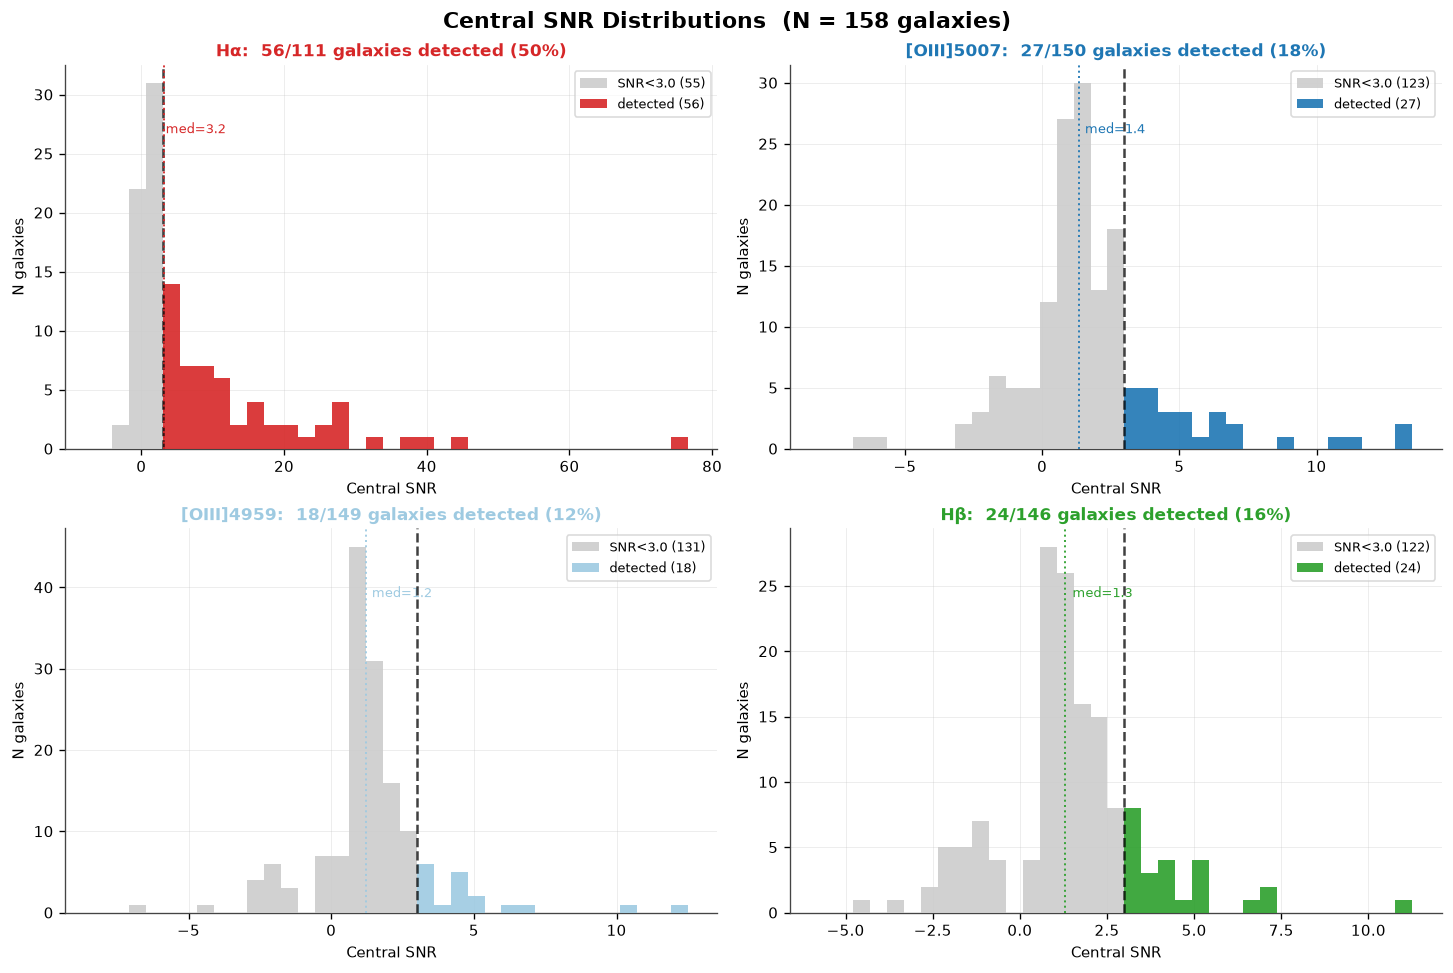

Saved → kmos_statistics_snr_hist.pdf


In [9]:
# ── SNR distribution histograms ──────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
fig.suptitle(f"Central SNR Distributions  (N = {len(sample)} galaxies)", fontsize=13, fontweight='bold')

for ax, (lbl, skey, ikey, lc) in zip(axes.ravel(), LINE_SNR_KEYS):
    s_  = sfx(skey)
    cov = [s for s in sample if s[ikey]]
    if not cov:
        ax.text(0.5, 0.5, 'no data', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(lbl, color=lc, fontsize=11)
        continue

    det     = [s[skey] for s in cov if s['det_' + s_]]
    low     = [s[skey] for s in cov if not s['det_' + s_] and np.isfinite(s[skey])]
    n_fail  = sum(1 for s in cov if not np.isfinite(s[skey]))
    vals    = det + low
    lo, hi  = min(min(vals) - 1, -3), max(max(vals), SNR_MIN + 2)
    bw      = (hi - lo) / 34                      # SNR_MIN is a bin edge
    bins    = SNR_MIN + bw * np.arange(np.floor((lo - SNR_MIN) / bw),
                                       np.ceil((hi - SNR_MIN) / bw) + 1)

    ax.hist([low, det], bins=bins, stacked=True,
            color=['#cccccc', lc], alpha=0.9, zorder=3,
            label=[f'SNR<{SNR_MIN} ({len(low)})', f'detected ({len(det)})'])
    ax.axvline(SNR_MIN, color='k', lw=1.5, ls='--', alpha=0.75, zorder=4)
    med = np.median(vals)
    ax.axvline(med, color=lc, lw=1.2, ls=':', alpha=0.9, zorder=4)
    ax.text(med + 0.2, ax.get_ylim()[1] * 0.85, f'med={med:.1f}', fontsize=8, color=lc, va='top')

    ax.set_title(f"{lbl}:  {len(det)}/{len(cov)} galaxies detected ({pct(len(det), len(cov))})"
                 + (f",  {n_fail} fit failed (not shown)" if n_fail else ""),
                 fontsize=10, color=lc)
    ax.set_xlabel("Central SNR", fontsize=9)
    ax.set_ylabel("N galaxies", fontsize=9)
    ax.legend(fontsize=8, framealpha=0.7)

plt.savefig("kmos_statistics_snr_hist.pdf", bbox_inches='tight')
plt.show()
print("Saved → kmos_statistics_snr_hist.pdf")


## Detection rates by field and band

Detected galaxies / galaxies whose data cover the line.  Detected = SNR ≥ SNR_MIN (S/N from `scripts/line_snr.py`; its artefact flags are reported but not used to reject).  Galaxies whose line is covered but not detected (or whose fit failed) stay in the denominator.

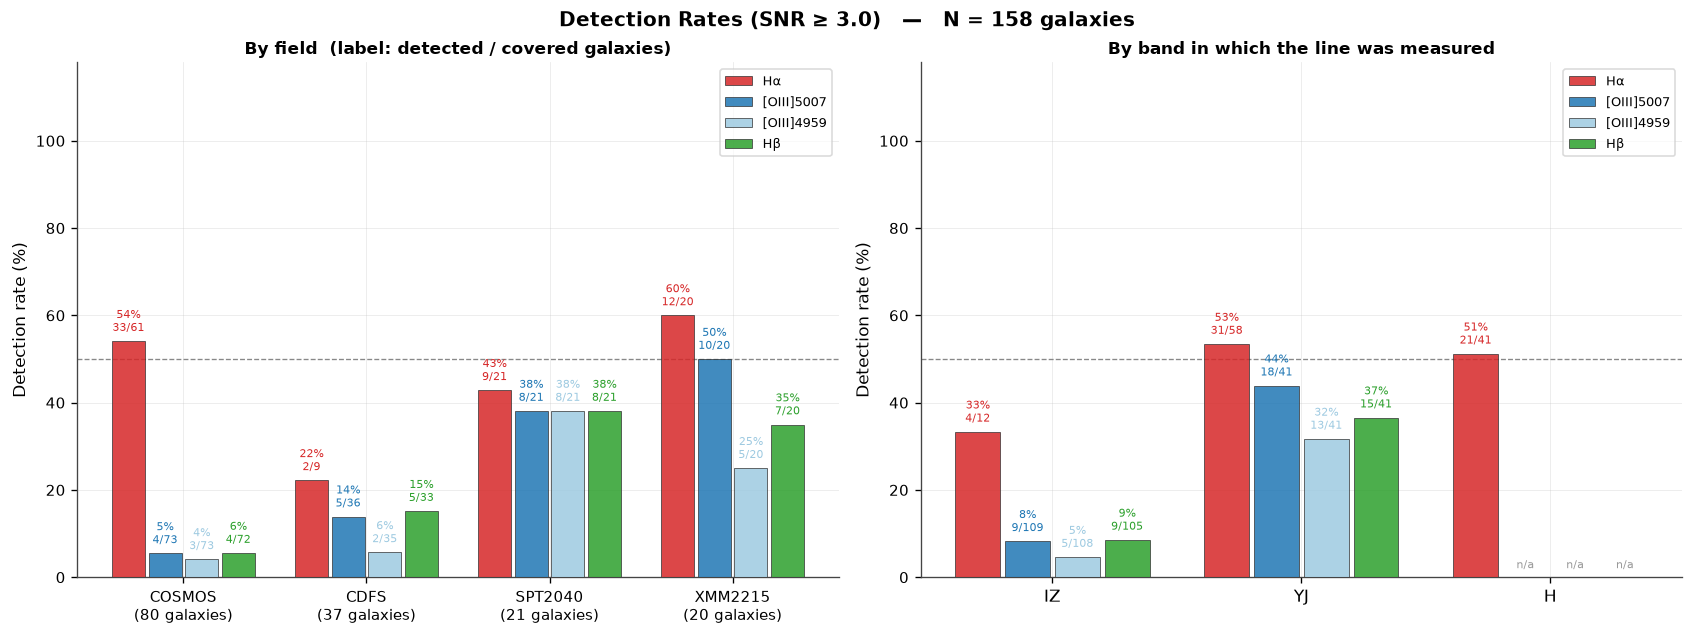

Saved → kmos_statistics_detection_rates.pdf


In [10]:
# ── Detection rates by field and by band ─────────────────────────────────────
# Bar label "k/n": k galaxies detected out of n galaxies whose data cover the line.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)
fig.suptitle(f"Detection Rates (SNR ≥ {SNR_MIN})   —   "
             f"N = {len(sample)} galaxies", fontsize=12, fontweight='bold')

def plot_detection_bars(ax, groups, subset, title):
    """subset(group, lbl) → (k_detected, n_covered)."""
    x  = np.arange(len(groups))
    bw = 0.8 / len(LINE_SNR_KEYS)
    for li, (lbl, skey, ikey, lc) in enumerate(LINE_SNR_KEYS):
        kn    = [subset(g, lbl) for g in groups]
        rates = [100 * k / n if n else 0 for k, n in kn]
        offs  = (li - (len(LINE_SNR_KEYS) - 1) / 2) * bw
        ax.bar(x + offs, rates, bw * 0.9, color=lc, alpha=0.85,
               edgecolor='#333', lw=0.5, label=lbl, zorder=3)
        for bi, (k, n) in enumerate(kn):
            ax.text(x[bi] + offs, rates[bi] + 1.5,
                    f"{pct(k, n)}\n{k}/{n}" if n else "n/a",
                    ha='center', va='bottom', fontsize=6.5, color=lc if n else '#999')
    ax.axhline(50, color='#888', lw=0.8, ls='--', zorder=1)
    ax.set_xticks(x)
    ax.set_xticklabels(groups, fontsize=10)
    ax.set_ylabel("Detection rate (%)", fontsize=10)
    ax.set_ylim(0, 118)
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, loc='upper right', framealpha=0.7)

field_labels = [f"{f}\n({sum(1 for s in sample if s['field'] == f)} galaxies)" for f in FIELDS_ORDER]
plot_detection_bars(axes[0], FIELDS_ORDER,
                    lambda f, lbl: det_count([s for s in sample if s['field'] == f], lbl),
                    "By field  (label: detected / covered galaxies)")
axes[0].set_xticklabels(field_labels, fontsize=9)

bands_used = [b for b in BANDS_ORDER
              if any(s['band_' + sfx(k)] == b for s in sample for _, k, _, _ in LINE_SNR_KEYS)]
plot_detection_bars(axes[1], bands_used,
                    lambda b, lbl: det_count(sample, lbl, band=b),
                    "By band in which the line was measured")

plt.savefig("kmos_statistics_detection_rates.pdf", bbox_inches='tight')
plt.show()
print("Saved → kmos_statistics_detection_rates.pdf")


## SNR vs. redshift

Filled markers = detected; hollow = SNR < threshold.  Colours = band.

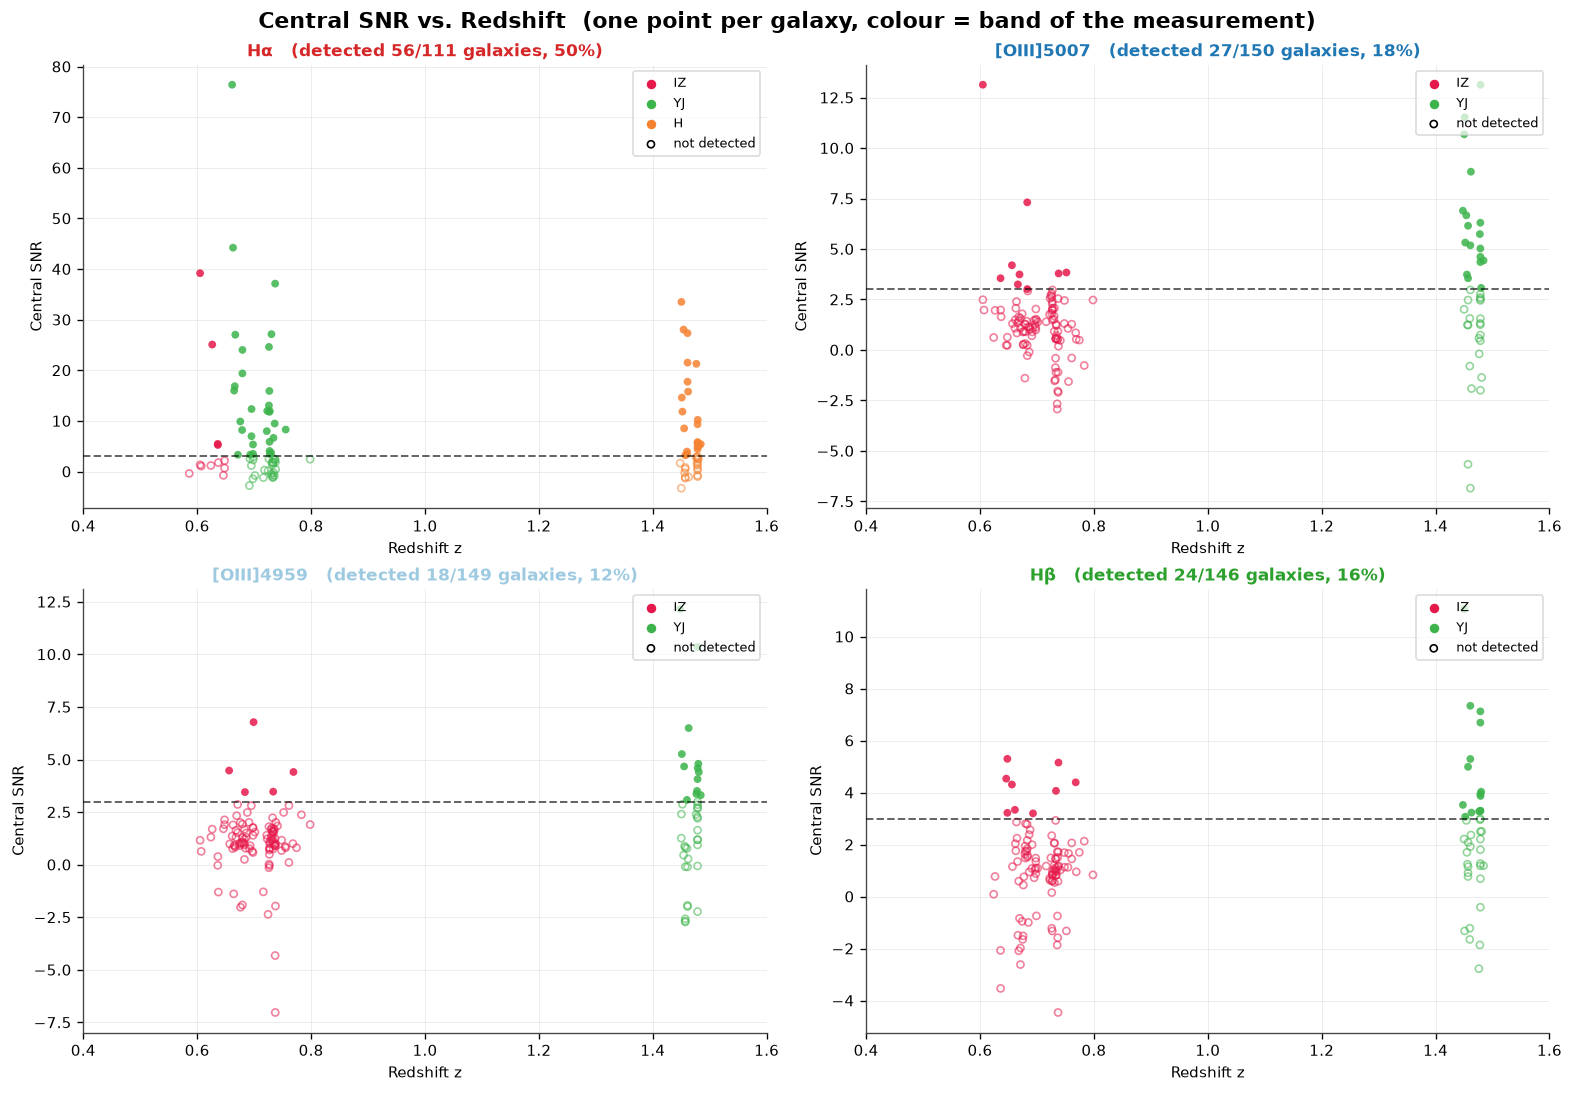

Saved → kmos_statistics_snr_z.pdf


In [11]:
# ── SNR vs. redshift scatter ─────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
fig.suptitle(f"Central SNR vs. Redshift  (one point per galaxy, colour = band of the measurement)",
             fontsize=13, fontweight='bold')

for ax, (lbl, skey, ikey, lc) in zip(axes.ravel(), LINE_SNR_KEYS):
    s_ = sfx(skey)
    bands_here = [b for b in BANDS_ORDER if any(s[ikey] and s['band_' + s_] == b for s in sample)]
    for band in bands_here:
        sub = [s for s in sample if s[ikey] and s['band_' + s_] == band and np.isfinite(s[skey])]
        bc  = BAND_COLORS.get(band, '#666')
        d   = [s for s in sub if s['det_' + s_]]
        nd  = [s for s in sub if not s['det_' + s_]]
        ax.scatter([s['z'] for s in d],  [s[skey] for s in d],  c=bc, s=22, alpha=0.85,
                   label=band, zorder=3, edgecolors='none')
        ax.scatter([s['z'] for s in nd], [s[skey] for s in nd], facecolors='none',
                   edgecolors=bc, s=18, alpha=0.55, zorder=2)

    ax.axhline(SNR_MIN, color='k', lw=1.2, ls='--', alpha=0.6, zorder=4)
    ax.set_xlabel("Redshift z", fontsize=9)
    ax.set_ylabel("Central SNR", fontsize=9)
    k, n = det_count(sample, lbl)
    ax.set_title(f"{lbl}   (detected {k}/{n} galaxies, {pct(k, n)})", fontsize=10, color=lc)
    handles = [plt.scatter([], [], c=BAND_COLORS.get(b, '#666'), s=22, label=b) for b in bands_here]
    handles.append(plt.scatter([], [], facecolors='none', edgecolors='k', s=18,
                               label='not detected'))
    ax.legend(handles=handles, fontsize=7.5, loc='upper right', framealpha=0.7)
    ax.set_xlim(0.4, 1.6)

plt.savefig("kmos_statistics_snr_z.pdf", bbox_inches='tight')
plt.show()
print("Saved → kmos_statistics_snr_z.pdf")


## SNR by field — violin plots

One violin per field per line. Points overlaid: coloured = detected, grey = below threshold.

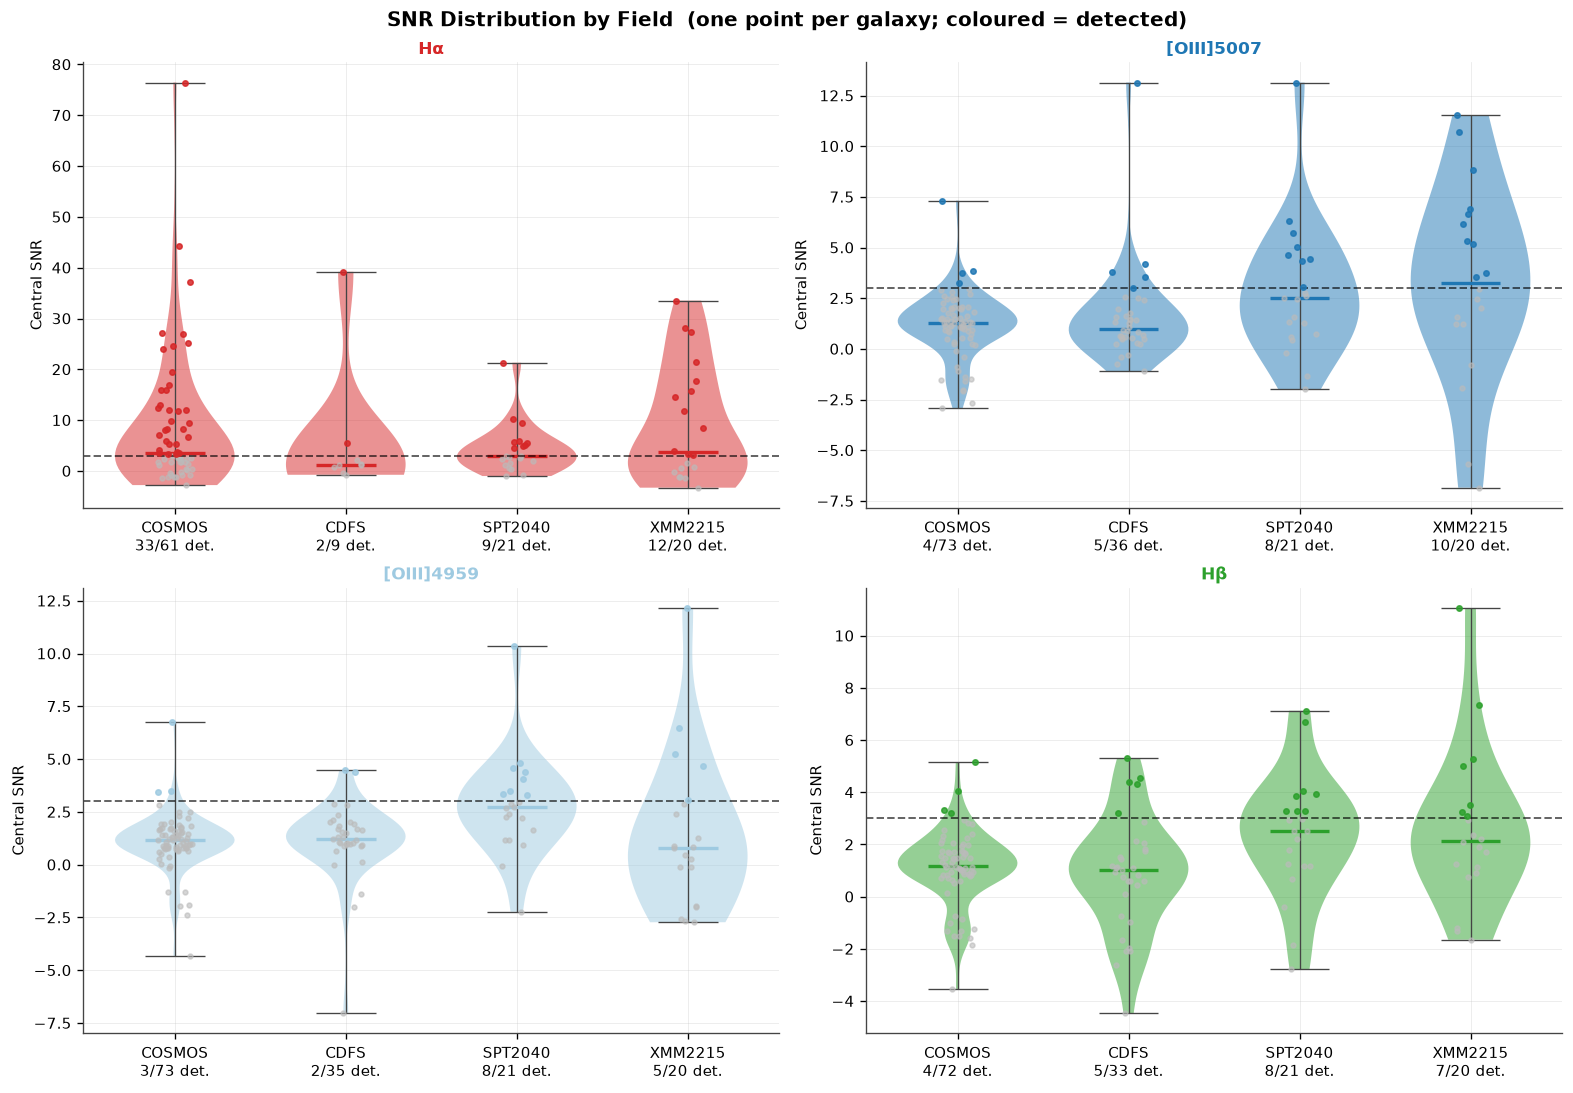

Saved → kmos_statistics_snr_by_field.pdf


In [12]:
# ── SNR violin / box plot by field ──────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
fig.suptitle(f"SNR Distribution by Field  (one point per galaxy; coloured = detected)",
             fontsize=12, fontweight='bold')

for ax, (lbl, skey, ikey, lc) in zip(axes.ravel(), LINE_SNR_KEYS):
    s_ = sfx(skey)
    data, labels = [], []
    for field in FIELDS_ORDER:
        sub = [s for s in sample if s['field'] == field and s[ikey] and np.isfinite(s[skey])]
        if sub:
            data.append(sub)
            k, n = det_count([s for s in sample if s['field'] == field], lbl)
            labels.append(f"{field}\n{k}/{n} det.")
    if not data:
        ax.set_title(lbl, color=lc); continue

    parts = ax.violinplot([[s[skey] for s in sub] for sub in data],
                          positions=np.arange(len(data)), showmedians=True,
                          showextrema=True, widths=0.7)
    for pc in parts['bodies']:
        pc.set_facecolor(lc); pc.set_alpha(0.5)
    parts['cmedians'].set_color(lc); parts['cmedians'].set_lw(2)
    for part in ['cbars', 'cmins', 'cmaxes']:
        parts[part].set_color('#444'); parts[part].set_lw(0.8)

    for xi, sub in enumerate(data):
        jit = np.random.default_rng(xi).uniform(-0.1, 0.1, len(sub))
        det = np.array([s['det_' + s_] for s in sub])
        y   = np.array([s[skey] for s in sub])
        ax.scatter(xi + jit[~det], y[~det], s=8,  color='#bbb', alpha=0.6, zorder=2)
        ax.scatter(xi + jit[det],  y[det],  s=10, color=lc,     alpha=0.85, zorder=3)

    ax.axhline(SNR_MIN, color='k', lw=1.2, ls='--', alpha=0.6)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_ylabel("Central SNR", fontsize=9)
    ax.set_title(lbl, fontsize=10, color=lc)

plt.savefig("kmos_statistics_snr_by_field.pdf", bbox_inches='tight')
plt.show()
print("Saved → kmos_statistics_snr_by_field.pdf")


## Mean SNR radial profiles

Mean ± 1 σ across detected galaxies in each annulus.

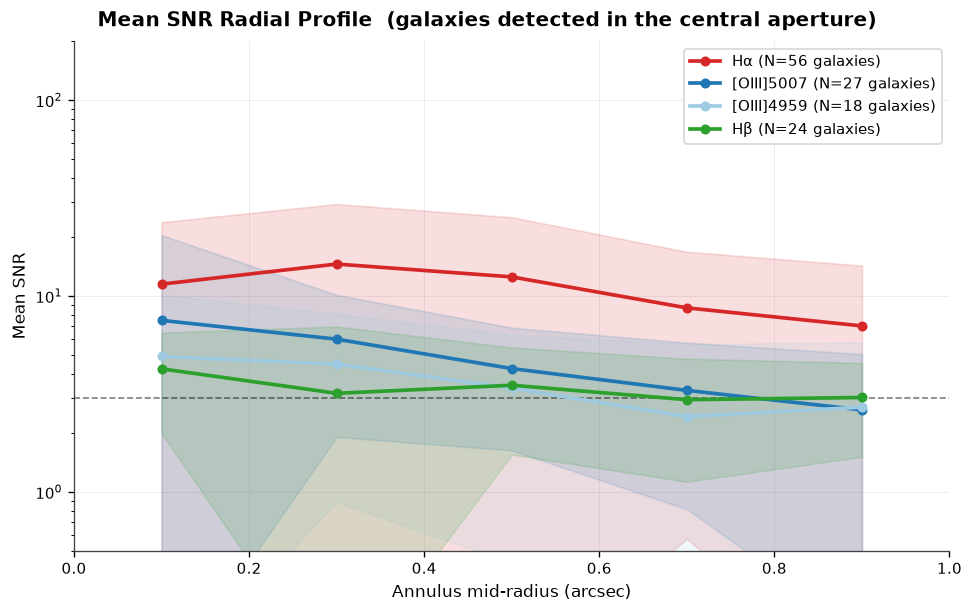

Saved → kmos_statistics_radial_mean.pdf


In [13]:
# ── Mean SNR radial profiles ─────────────────────────────────────────────────
edges  = ANNULUS_EDGES
n_ann  = len(edges) - 1
r_mid  = [(edges[i] + edges[i+1]) / 2 * SPAXEL_SCALE for i in range(n_ann)]

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
fig.suptitle("Mean SNR Radial Profile  (galaxies detected in the central aperture)",
             fontsize=12, fontweight='bold')

for lbl, skey, ikey, lc in LINE_SNR_KEYS:
    det_gals = [s for s in sample if s['det_' + sfx(skey)]]
    if not det_gals:
        continue
    mat = np.array([[v if np.isfinite(v) else np.nan
                     for v in s['ann_snrs'].get(lbl, [np.nan] * n_ann)]
                    for s in det_gals], dtype=float)
    with np.errstate(all='ignore'), warnings.catch_warnings():
        warnings.simplefilter("ignore")
        mean = np.nanmean(mat, axis=0)
        std  = np.nanstd(mat,  axis=0)

    ax.plot(r_mid, mean, color=lc, lw=2.2, marker='o', ms=5,
            label=f"{lbl} (N={len(det_gals)} galaxies)", zorder=3)
    ax.fill_between(r_mid, np.clip(mean - std, 0.1, None), mean + std,
                    color=lc, alpha=0.15, zorder=2)

ax.axhline(SNR_MIN, color='k', lw=1.0, ls='--', alpha=0.5)
ax.set_xlabel('Annulus mid-radius (arcsec)', fontsize=10)
ax.set_ylabel('Mean SNR', fontsize=10)
ax.legend(fontsize=9, framealpha=0.8)
ax.set_xlim(0, edges[-1] * SPAXEL_SCALE)
ax.set_yscale('log')
ax.set_ylim(0.5, 200)

plt.savefig("kmos_statistics_radial_mean.pdf", bbox_inches='tight')
plt.show()
print("Saved → kmos_statistics_radial_mean.pdf")


## Hα radial profiles by field

Mean ± 1 σ per field (light lines = individual galaxies).

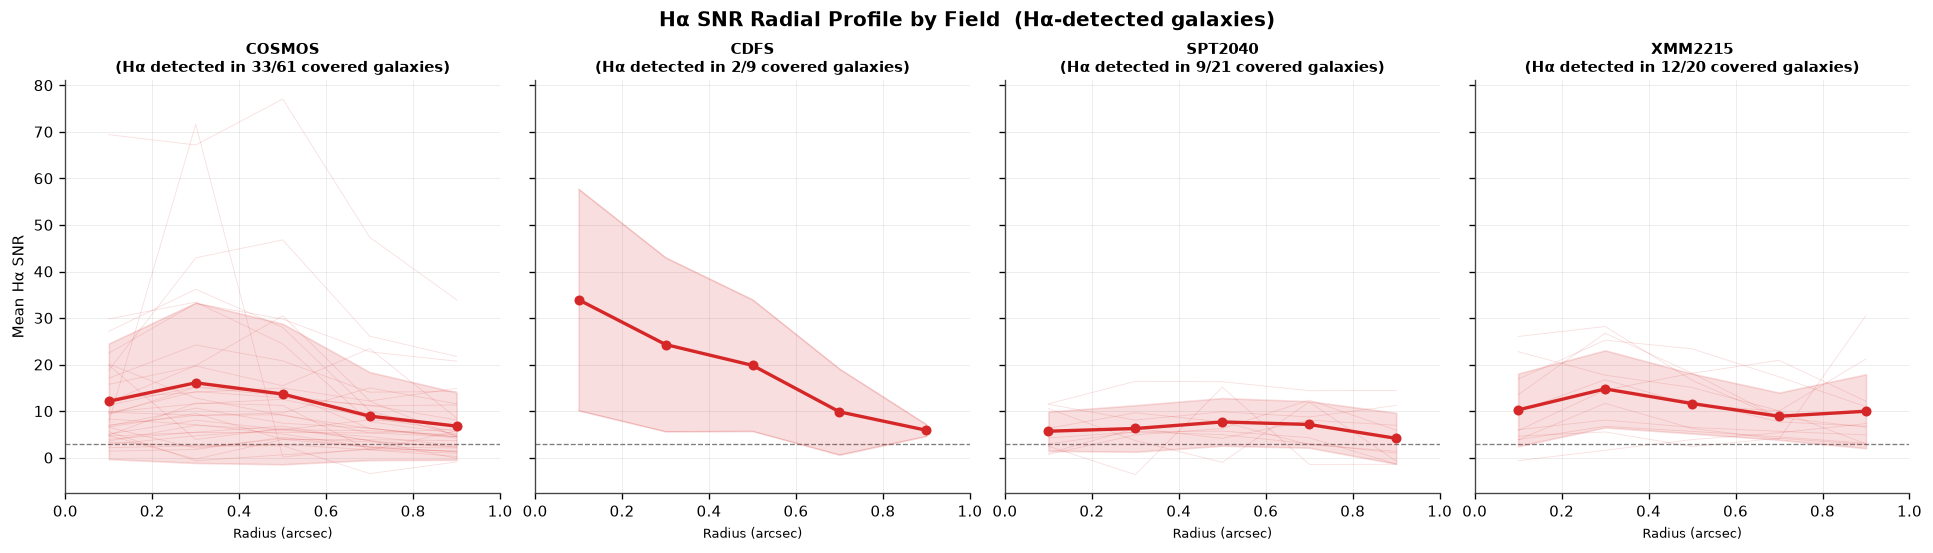

Saved → kmos_statistics_radial_by_field.pdf


In [14]:
# ── Mean radial profiles split by field ──────────────────────────────────────
lbl_ha, skey_ha, ikey_ha, lc_ha = LINE_SNR_KEYS[0]   # Hα

fig, axes = plt.subplots(1, len(FIELDS_ORDER), figsize=(4 * len(FIELDS_ORDER), 4.5),
                         sharey=True, constrained_layout=True)
if len(FIELDS_ORDER) == 1:
    axes = [axes]
fig.suptitle("Hα SNR Radial Profile by Field  (Hα-detected galaxies)",
             fontsize=12, fontweight='bold')

for ax, field in zip(axes, FIELDS_ORDER):
    sub = [s for s in sample if s['field'] == field and s['det_' + sfx(skey_ha)]]
    k, n = det_count([s for s in sample if s['field'] == field], lbl_ha)
    ax.set_title(f"{field}\n(Hα detected in {k}/{n} covered galaxies)", fontsize=9)
    ax.set_xlabel('Radius (arcsec)', fontsize=8)
    if ax == axes[0]:
        ax.set_ylabel('Mean Hα SNR', fontsize=9)
    ax.axhline(SNR_MIN, color='k', lw=0.8, ls='--', alpha=0.5)

    if not sub:
        ax.text(0.5, 0.5, 'Hα not covered' if n == 0 else 'no detections',
                ha='center', va='center', transform=ax.transAxes, color='#aaa')
        continue

    mat = np.array([[v if np.isfinite(v) else np.nan
                     for v in s['ann_snrs'].get('Hα', [np.nan] * n_ann)]
                    for s in sub], dtype=float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        mean = np.nanmean(mat, axis=0)
        std  = np.nanstd(mat, axis=0)

    ax.plot(r_mid, mean, color=lc_ha, lw=2, marker='o', ms=5, zorder=3)
    ax.fill_between(r_mid, mean - std, mean + std, color=lc_ha, alpha=0.15, zorder=2)
    for row in mat:
        ax.plot(r_mid, row, color=lc_ha, lw=0.5, alpha=0.15, zorder=1)
    ax.set_xlim(0, edges[-1] * SPAXEL_SCALE)

plt.savefig("kmos_statistics_radial_by_field.pdf", bbox_inches='tight')
plt.show()
print("Saved → kmos_statistics_radial_by_field.pdf")


## Exposure time vs. SNR

Left: Hα coloured by field. Right: all lines.

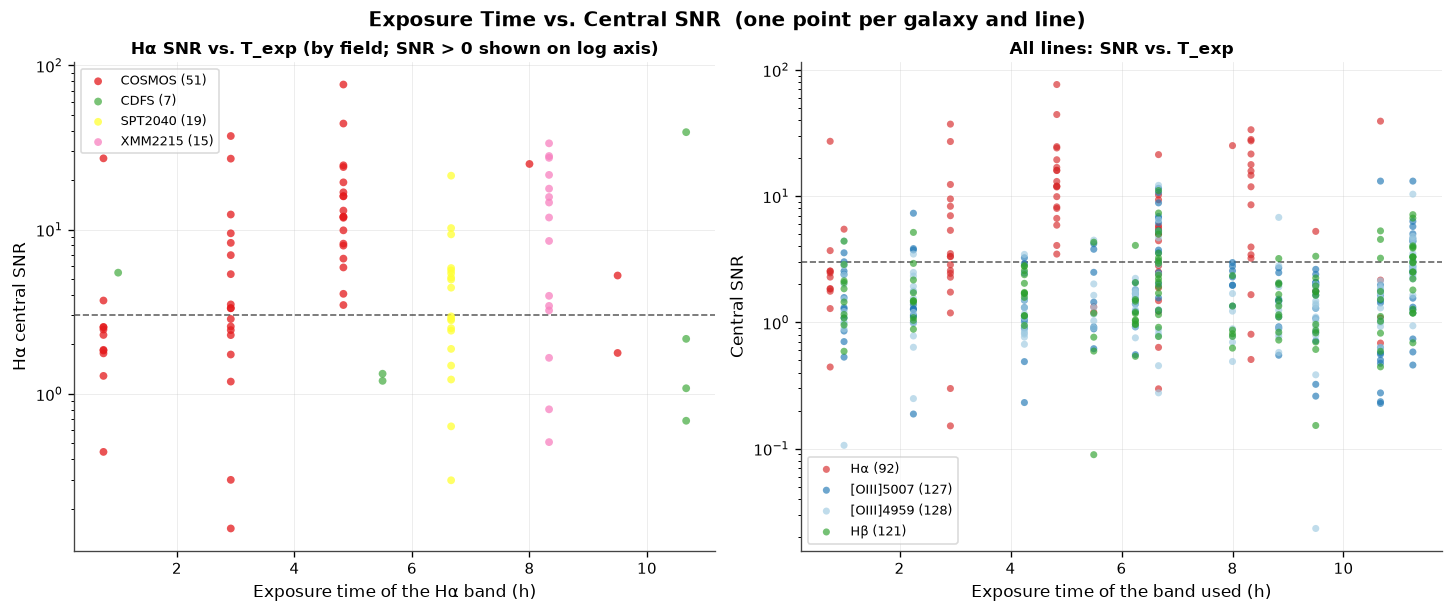

Saved → kmos_statistics_texp_snr.pdf


In [15]:
# ── Exposure time vs. central SNR ────────────────────────────────────────────
# x = exposure time of the cube(s) in which the line was measured (not the sum
#     over all bands of the galaxy).
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
fig.suptitle("Exposure Time vs. Central SNR  (one point per galaxy and line)",
             fontsize=12, fontweight='bold')

ax = axes[0]
field_palette = plt.cm.Set1(np.linspace(0, 0.85, len(FIELDS_ORDER)))
for fi, field in enumerate(FIELDS_ORDER):
    sub = [s for s in sample if s['field'] == field and s['in_range_ha']
           and np.isfinite(s['snr_ha']) and s['snr_ha'] > 0]
    if not sub:
        continue
    ax.scatter([s['texp_ha'] for s in sub], [s['snr_ha'] for s in sub],
               c=[field_palette[fi]], s=22, alpha=0.75,
               label=f"{field} ({len(sub)})", zorder=3, edgecolors='none')
ax.axhline(SNR_MIN, color='k', lw=1.0, ls='--', alpha=0.6)
ax.set_xlabel('Exposure time of the Hα band (h)', fontsize=10)
ax.set_ylabel('Hα central SNR', fontsize=10)
ax.set_title('Hα SNR vs. T_exp (by field; SNR > 0 shown on log axis)', fontsize=10)
ax.set_yscale('log')
ax.legend(fontsize=7.5, framealpha=0.7)

ax = axes[1]
for lbl, skey, ikey, lc in LINE_SNR_KEYS:
    s_  = sfx(skey)
    sub = [s for s in sample if s[ikey] and np.isfinite(s[skey]) and s[skey] > 0]
    if not sub:
        continue
    ax.scatter([s['texp_' + s_] for s in sub], [s[skey] for s in sub],
               c=lc, s=18, alpha=0.65, label=f"{lbl} ({len(sub)})", zorder=3, edgecolors='none')
ax.axhline(SNR_MIN, color='k', lw=1.0, ls='--', alpha=0.6)
ax.set_xlabel('Exposure time of the band used (h)', fontsize=10)
ax.set_ylabel('Central SNR', fontsize=10)
ax.set_title('All lines: SNR vs. T_exp', fontsize=10)
ax.legend(fontsize=8, framealpha=0.7)
ax.set_yscale('log')

plt.savefig("kmos_statistics_texp_snr.pdf", bbox_inches='tight')
plt.show()
print("Saved → kmos_statistics_texp_snr.pdf")


## Redshift distribution

Left: stacked histogram by band. Right: violin by field.

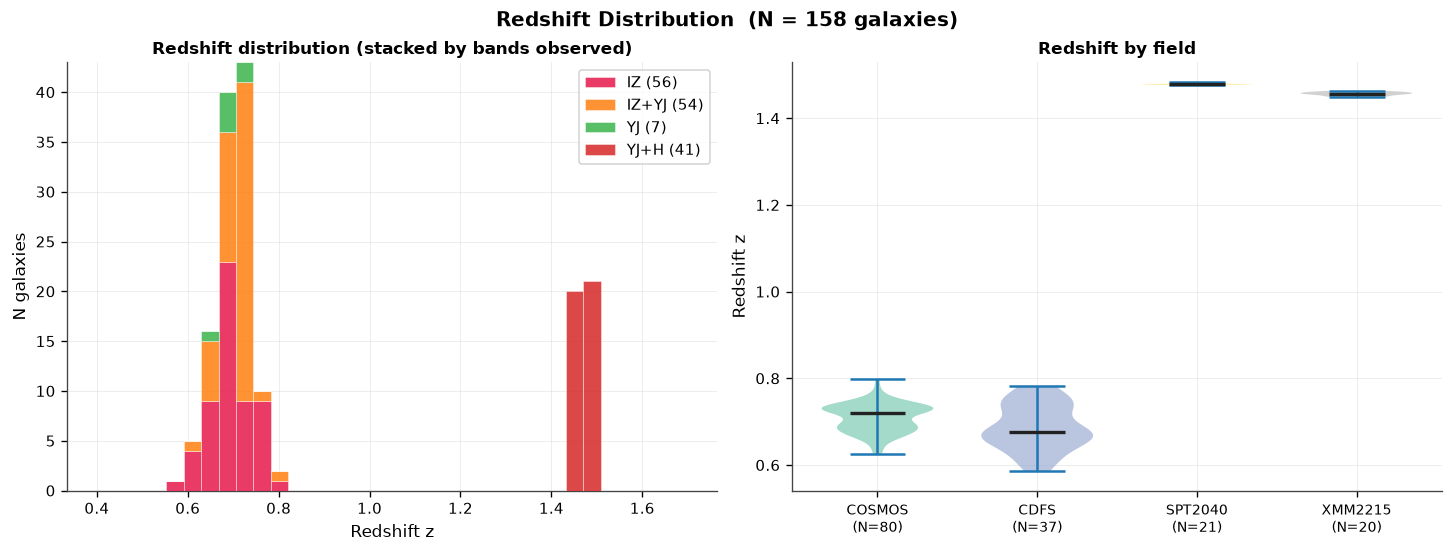

Saved → kmos_statistics_zdist.pdf


In [16]:
# ── Redshift distribution ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
fig.suptitle(f"Redshift Distribution  (N = {len(sample)} galaxies)", fontsize=12, fontweight='bold')

# Left: z histogram, one count per galaxy, stacked by the bands it was observed in
ax = axes[0]
combos = sorted({s['bands'] for s in sample},
                key=lambda c: (band_rank(c.split('+')[0]), len(c)))
combo_colors = {c: BAND_COLORS.get(c, plt.cm.tab10(i % 10)) for i, c in enumerate(combos)}
bins = np.linspace(0.4, 1.7, 35)
bottom = np.zeros(len(bins) - 1)
for combo in combos:
    zs = [s['z'] for s in sample if s['bands'] == combo]
    n, _ = np.histogram(zs, bins=bins)
    ax.bar(bins[:-1], n, width=np.diff(bins), align='edge', bottom=bottom,
           color=combo_colors[combo], alpha=0.85, label=f"{combo} ({len(zs)})",
           edgecolor='white', lw=0.3, zorder=3)
    bottom += n
ax.set_xlabel('Redshift z', fontsize=10)
ax.set_ylabel('N galaxies', fontsize=10)
ax.set_title('Redshift distribution (stacked by bands observed)', fontsize=10)
ax.legend(fontsize=9)

# Right: z by field (violin)
ax = axes[1]
data   = [[s['z'] for s in sample if s['field'] == f] for f in FIELDS_ORDER]
labels = [f"{f}\n(N={len(d)})" for f, d in zip(FIELDS_ORDER, data)]
parts  = ax.violinplot(data, positions=np.arange(len(data)), showmedians=True, widths=0.7)
colors = plt.cm.Set2(np.linspace(0, 1, len(FIELDS_ORDER)))
for pc, c in zip(parts['bodies'], colors):
    pc.set_facecolor(c); pc.set_alpha(0.6)
parts['cmedians'].set_lw(2); parts['cmedians'].set_color('#222')
ax.set_xticks(np.arange(len(labels)))
ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylabel('Redshift z', fontsize=10)
ax.set_title('Redshift by field', fontsize=10)

plt.savefig("kmos_statistics_zdist.pdf", bbox_inches='tight')
plt.show()
print("Saved → kmos_statistics_zdist.pdf")


## Data depth, SNR efficiency and spatial-scale projections

For each galaxy we compute:
- **SNR efficiency** η = SNR / √T_exp  (expected to be constant if noise-dominated)
- **Minimum spatial bin** (arcsec & kpc) at which emission is detectable at SNR ≥ 3
- **Projection**: expected SNR and resolvable scale if extra archival hours are added

Key formula: SNR ∝ √T  →  SNR_new = SNR_old × √(T_new / T_old)
Spatial scale: a 5×5-spaxel aperture sums ~25 spaxels, so SNR_per_spaxel ≈ SNR_aperture / 5.
Minimum bin of n spaxels to reach SNR ≥ 3: n_min = (3 / SNR_spaxel)².
Drizzling to 0.1″/pix halves SNR per pixel; minimum drizzled scale is 0.1″ × 3 / SNR_{0.1}.


In [17]:
# ── SNR efficiency and spatial-scale analysis ─────────────────────────────────
from astropy.cosmology import FlatLambdaCDM
_cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

def kpc_per_arcsec(z):
    return float(_cosmo.kpc_proper_per_arcmin(z).value / 60.0)

# ── Tunable parameters ─────────────────────────────────────────────────────────
SPAXEL_ARCSEC  = 0.2    # KMOS native pixel
DRIZZLE_ARCSEC = 0.1    # drizzled output pixel (pixfrac ~0.7)
AP_NPIX        = 25.0   # 5×5 aperture used in line_snr
SNR_SCI        = 3.0    # minimum SNR per spatial bin for science
T_ARCHIVE_H    = 10.0   # hypothetical extra hours from the ESO archive

# ── Per-galaxy depth metrics ───────────────────────────────────────────────────
depth_rows = []
# one row per galaxy: SNR of its primary line (Hα, else [OIII]5007, else Hβ, …) and
# the exposure time of the band in which that line was measured
for s in sample:
    pl = s['primary_line']
    if pl is None:
        continue
    snr_c = s[SNR_KEY_MAP[pl]]
    texp  = s['texp_' + sfx(SNR_KEY_MAP[pl])]
    z     = s['z']
    if not (np.isfinite(snr_c) and snr_c > 0 and texp > 0):
        continue

    kpas         = kpc_per_arcsec(z)
    snr_spaxel   = snr_c / np.sqrt(AP_NPIX)         # per native 0.2″ spaxel
    efficiency   = snr_c / np.sqrt(texp)             # SNR / √hour

    # native resolution (0.2″ bins)
    n_min        = max((SNR_SCI / snr_spaxel) ** 2, 1.0)
    scale_nat    = SPAXEL_ARCSEC * np.sqrt(n_min)   # arcsec

    # drizzled (0.1″ pix): SNR per 0.1″ pixel = snr_spaxel × (0.1/0.2) = snr_spaxel/2
    snr_drz      = snr_spaxel * (DRIZZLE_ARCSEC / SPAXEL_ARCSEC)
    n_min_drz    = max((SNR_SCI / snr_drz) ** 2, 1.0)
    scale_drz    = DRIZZLE_ARCSEC * np.sqrt(n_min_drz)

    # projection with extra archive time
    texp_tot      = texp + T_ARCHIVE_H
    snr_proj      = snr_c * np.sqrt(texp_tot / texp)
    snr_sp_proj   = snr_proj / np.sqrt(AP_NPIX)
    n_min_proj    = max((SNR_SCI / snr_sp_proj) ** 2, 1.0)
    scale_proj    = SPAXEL_ARCSEC * np.sqrt(n_min_proj)
    snr_drz_proj  = snr_sp_proj * (DRIZZLE_ARCSEC / SPAXEL_ARCSEC)
    n_min_dp      = max((SNR_SCI / snr_drz_proj) ** 2, 1.0)
    scale_drz_proj = DRIZZLE_ARCSEC * np.sqrt(n_min_dp)

    depth_rows.append(dict(
        group_id        = s['group_id'],
        field           = s['field'],
        band            = s['band_' + sfx(SNR_KEY_MAP[pl])],
        primary_line    = pl,
        detected        = s['det_' + sfx(SNR_KEY_MAP[pl])],
        z               = z,
        texp_h          = texp,
        snr_c           = snr_c,
        efficiency      = efficiency,
        scale_nat_as    = scale_nat,
        scale_nat_kpc   = scale_nat   * kpas,
        scale_drz_as    = scale_drz,
        scale_drz_kpc   = scale_drz   * kpas,
        snr_proj        = snr_proj,
        scale_proj_as   = scale_proj,
        scale_proj_kpc  = scale_proj  * kpas,
        scale_drz_proj_as  = scale_drz_proj,
        scale_drz_proj_kpc = scale_drz_proj * kpas,
        kpas            = kpas,
    ))

# ── Summary printout ───────────────────────────────────────────────────────────
med = lambda key: np.nanmedian([r[key] for r in depth_rows])
pct = lambda key, p: np.nanpercentile([r[key] for r in depth_rows], p)

print(f"{'='*68}")
print(f"  DATA DEPTH SUMMARY   ({len(depth_rows)} galaxies with primary-line SNR > 0, "
      f"{sum(r['detected'] for r in depth_rows)} of them detected)")
print(f"{'='*68}")
print(f"\nMEDIAN values across these galaxies:")
print(f"  Exposure time          {med('texp_h'):6.1f} h")
print(f"  Central SNR            {med('snr_c'):6.1f}")
print(f"  SNR efficiency η       {med('efficiency'):6.2f}  [SNR / √hour]")
print(f"\nMINIMUM resolvable spatial scale (SNR ≥ {SNR_SCI:.0f}):")
print(f"  Native 0.2″ binning    {med('scale_nat_as'):5.2f}″  =  {med('scale_nat_kpc'):5.2f} kpc  (median)")
print(f"  Drizzled 0.1″ pixels   {med('scale_drz_as'):5.2f}″  =  {med('scale_drz_kpc'):5.2f} kpc  (median)")
print(f"\nWith +{T_ARCHIVE_H:.0f} h extra archival data (total = current + {T_ARCHIVE_H:.0f} h):")
print(f"  Projected median SNR   {med('snr_proj'):6.1f}")
print(f"  Native min scale       {med('scale_proj_as'):5.2f}″  =  {med('scale_proj_kpc'):5.2f} kpc")
print(f"  Drizzled min scale     {med('scale_drz_proj_as'):5.2f}″  =  {med('scale_drz_proj_kpc'):5.2f} kpc")
print()
print(f"Best-case (top 10% SNR):  native {pct('scale_nat_as',10):.2f}″  drizzled {pct('scale_drz_as',10):.2f}″")


  DATA DEPTH SUMMARY   (133 galaxies with primary-line SNR > 0, 63 of them detected)

MEDIAN values across these galaxies:
  Exposure time             4.8 h
  Central SNR               2.9
  SNR efficiency η         1.67  [SNR / √hour]

MINIMUM resolvable spatial scale (SNR ≥ 3):
  Native 0.2″ binning     1.05″  =   8.55 kpc  (median)
  Drizzled 0.1″ pixels    1.05″  =   8.55 kpc  (median)

With +10 h extra archival data (total = current + 10 h):
  Projected median SNR      6.4
  Native min scale        0.47″  =   3.53 kpc
  Drizzled min scale      0.47″  =   3.53 kpc

Best-case (top 10% SNR):  native 0.20″  drizzled 0.14″


### Figures: SNR efficiency · depth projection · spatial scale achievable


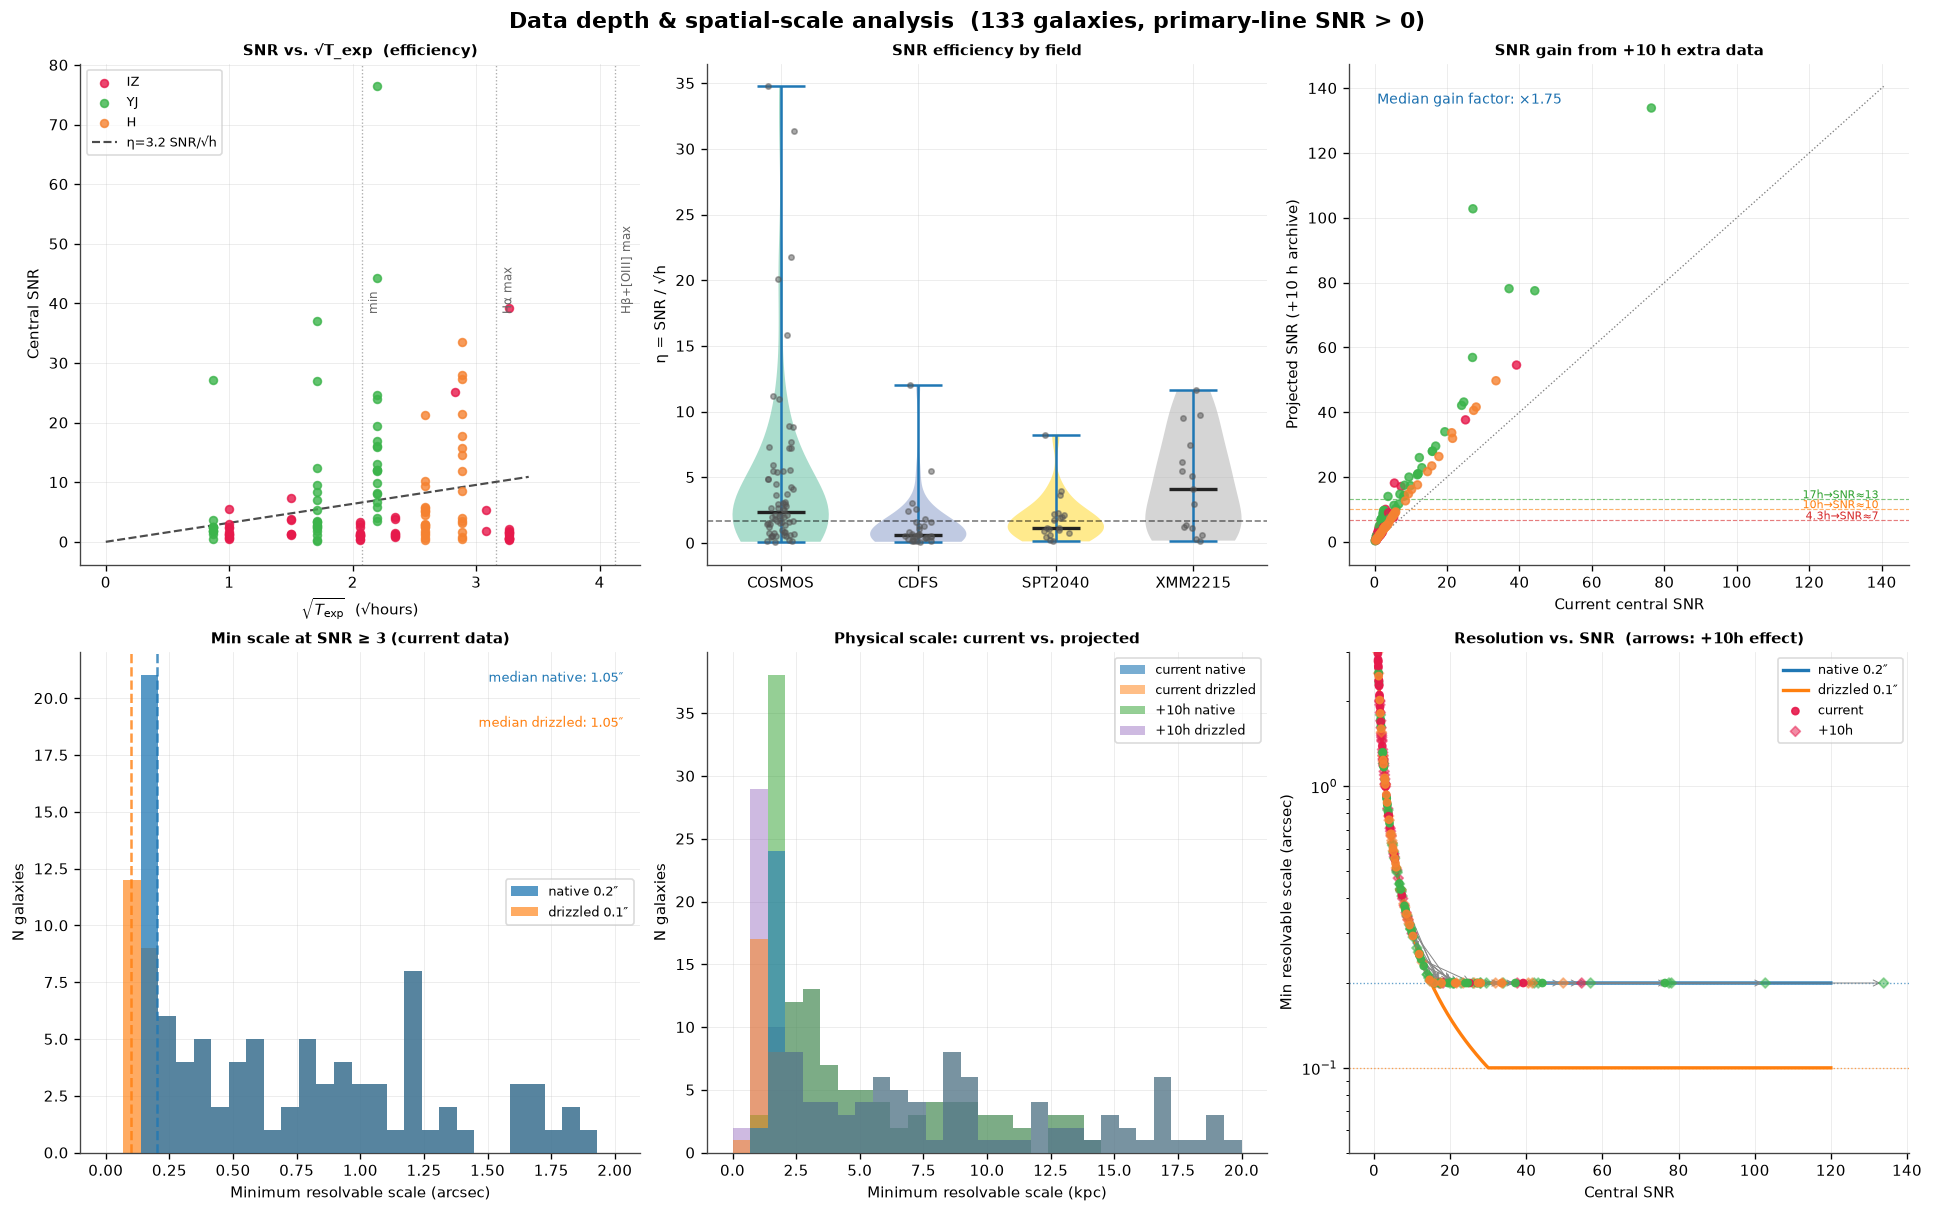

Saved → kmos_statistics_depth.pdf

────────────────────────────────────────────────────────────────────
HEADLINE NUMBERS
────────────────────────────────────────────────────────────────────
  We observed a median of 4.8 h per galaxy and achieved a median
  central SNR of 2.9, enabling spatially resolved emission-line
  measurements on scales of 1.05" (8.5 kpc) with native 0.2"/spaxel
  binning (SNR≥3 per spatial element); at this SNR level,
  drizzling to 0.1"/pix gives the same minimum scale (1.05", 8.5 kpc).

  With an additional 10 h of archival data (total 14.8 h),
  the projected median SNR rises to 6.4, reducing the
  minimum resolvable scale to 0.47" (3.5 kpc) natively
  and 0.47" (3.5 kpc) with drizzling.
────────────────────────────────────────────────────────────────────


In [18]:
# ── Figure: SNR efficiency, depth projection, spatial scale ───────────────────
fig = plt.figure(figsize=(16, 10), constrained_layout=True)
fig.suptitle(
    f"Data depth & spatial-scale analysis  ({len(depth_rows)} galaxies, primary-line SNR > 0)",
    fontsize=13, fontweight='bold',
)
gs = fig.add_gridspec(2, 3)

# ── Panel A: SNR vs √T_exp  (efficiency) ─────────────────────────────────────
ax = fig.add_subplot(gs[0, 0])
for band in ['IZ', 'YJ', 'H', 'HK', '??']:
    sub = [r for r in depth_rows if r['band'] == band]
    if not sub:
        continue
    xs = np.sqrt([r['texp_h'] for r in sub])
    ys = [r['snr_c'] for r in sub]
    ax.scatter(xs, ys, c=BAND_COLORS.get(band,'#aaa'), s=22, alpha=0.8, label=band, zorder=3)

# fit a single efficiency line η through origin
xs_all = np.sqrt([r['texp_h'] for r in depth_rows])
ys_all = np.array([r['snr_c'] for r in depth_rows])
eta    = float(np.dot(xs_all, ys_all) / np.dot(xs_all, xs_all))
t_fit  = np.linspace(0, max([r['texp_h'] for r in depth_rows]) * 1.1, 80)
ax.plot(np.sqrt(t_fit), eta * np.sqrt(t_fit), 'k--', lw=1.3, alpha=0.7,
        label=f'η={eta:.1f} SNR/√h')

for t_h, lbl in [(4.3, 'min'), (10, 'Hα max'), (17, 'Hβ+[OIII] max')]:
    ax.axvline(np.sqrt(t_h), color='#888', lw=0.8, ls=':', alpha=0.7)
    ax.text(np.sqrt(t_h)+0.05, 0.5, lbl, fontsize=7, color='#666',
            rotation=90, va='bottom', transform=ax.get_xaxis_transform())

ax.set_xlabel(r'$\sqrt{T_{\rm exp}}$  (√hours)', fontsize=9)
ax.set_ylabel('Central SNR', fontsize=9)
ax.set_title('SNR vs. √T_exp  (efficiency)', fontsize=9)
ax.legend(fontsize=7.5, loc='upper left', framealpha=0.7)

# ── Panel B: SNR efficiency per field (violin) ────────────────────────────────
ax = fig.add_subplot(gs[0, 1])
fields_ord = sorted(set(r['field'] for r in depth_rows),
                    key=lambda f: -sum(1 for r in depth_rows if r['field']==f))
eff_by_field = [[r['efficiency'] for r in depth_rows if r['field']==f] for f in fields_ord]
if any(eff_by_field):
    parts = ax.violinplot(eff_by_field, positions=np.arange(len(fields_ord)),
                          showmedians=True, widths=0.7)
    colors_vp = plt.cm.Set2(np.linspace(0, 1, len(fields_ord)))
    for pc, c in zip(parts['bodies'], colors_vp):
        pc.set_facecolor(c); pc.set_alpha(0.55)
    parts['cmedians'].set_lw(2); parts['cmedians'].set_color('#222')
    for bi, (d, lbl) in enumerate(zip(eff_by_field, fields_ord)):
        jit = np.random.default_rng(bi).uniform(-0.1,0.1,len(d))
        ax.scatter(bi + jit, d, s=10, color='#555', alpha=0.5, zorder=3)
ax.set_xticks(np.arange(len(fields_ord)))
ax.set_xticklabels(fields_ord, fontsize=9, rotation=0, ha='center')
ax.set_ylabel('η = SNR / √h', fontsize=9)
ax.set_title('SNR efficiency by field', fontsize=9)
ax.axhline(np.nanmedian([r['efficiency'] for r in depth_rows]),
           color='k', lw=1, ls='--', alpha=0.5)

# ── Panel C: Projected SNR with extra archive hours ────────────────────────────
ax = fig.add_subplot(gs[0, 2])
current_snrs = [r['snr_c']    for r in depth_rows]
proj_snrs    = [r['snr_proj'] for r in depth_rows]
ax.scatter(current_snrs, proj_snrs,
           c=[BAND_COLORS.get(r['band'],'#aaa') for r in depth_rows],
           s=22, alpha=0.8, zorder=3)
lim = max(max(proj_snrs), max(current_snrs)) * 1.05
lo  = min(min(current_snrs), 0)
ax.plot([lo, lim], [lo, lim], 'k:', lw=0.8, alpha=0.5, label='no change')
ax.set_xlabel('Current central SNR', fontsize=9)
ax.set_ylabel(f'Projected SNR (+{T_ARCHIVE_H:.0f} h archive)', fontsize=9)
ax.set_title(f'SNR gain from +{T_ARCHIVE_H:.0f} h extra data', fontsize=9)
gain = np.sqrt((np.median([r['texp_h'] for r in depth_rows]) + T_ARCHIVE_H)
               / np.median([r['texp_h'] for r in depth_rows]))
ax.text(0.05, 0.92, f'Median gain factor: ×{gain:.2f}',
        transform=ax.transAxes, fontsize=8.5, color='#1a6faf')
for h, clr in [(4.3,'#d62728'),(10,'#ff7f0e'),(17,'#2ca02c')]:
    snr_h = eta * np.sqrt(h)
    ax.axhline(snr_h, color=clr, lw=0.7, ls='--', alpha=0.6)
    ax.text(lim*0.99, snr_h+0.3, f'{h}h→SNR≈{snr_h:.0f}', fontsize=6.5,
            color=clr, ha='right')

# ── Panel D: Min spatial scale (current) ──────────────────────────────────────
ax = fig.add_subplot(gs[1, 0])
scales_nat = [r['scale_nat_as'] for r in depth_rows]
scales_drz = [r['scale_drz_as'] for r in depth_rows]
bins_s = np.linspace(0, 2.0, 30)
ax.hist(scales_nat, bins=bins_s, color='#1f77b4', alpha=0.75, label='native 0.2″', zorder=3)
ax.hist(scales_drz, bins=bins_s, color='#ff7f0e', alpha=0.65, label='drizzled 0.1″', zorder=2)
ax.axvline(SPAXEL_ARCSEC,  color='#1f77b4', lw=1.5, ls='--', alpha=0.8)
ax.axvline(DRIZZLE_ARCSEC, color='#ff7f0e', lw=1.5, ls='--', alpha=0.8)
ax.set_xlabel('Minimum resolvable scale (arcsec)', fontsize=9)
ax.set_ylabel('N galaxies', fontsize=9)
ax.set_title(f'Min scale at SNR ≥ {SNR_SCI:.0f} (current data)', fontsize=9)
ax.legend(fontsize=8, framealpha=0.7)
ax.text(0.97, 0.94, f'median native: {np.median(scales_nat):.2f}″',
        transform=ax.transAxes, ha='right', fontsize=8, color='#1f77b4')
ax.text(0.97, 0.85, f'median drizzled: {np.median(scales_drz):.2f}″',
        transform=ax.transAxes, ha='right', fontsize=8, color='#ff7f0e')

# ── Panel E: Min scale in kpc ─────────────────────────────────────────────────
ax = fig.add_subplot(gs[1, 1])
kpc_nat  = [r['scale_nat_kpc']  for r in depth_rows]
kpc_drz  = [r['scale_drz_kpc']  for r in depth_rows]
kpc_proj = [r['scale_proj_kpc'] for r in depth_rows]
kpc_dp   = [r['scale_drz_proj_kpc'] for r in depth_rows]
bins_k   = np.linspace(0, 20, 30)
ax.hist(kpc_nat,  bins=bins_k, color='#1f77b4', alpha=0.6, label='current native', zorder=4)
ax.hist(kpc_drz,  bins=bins_k, color='#ff7f0e', alpha=0.5, label='current drizzled', zorder=3)
ax.hist(kpc_proj, bins=bins_k, color='#2ca02c', alpha=0.5, label=f'+{T_ARCHIVE_H:.0f}h native', zorder=2)
ax.hist(kpc_dp,   bins=bins_k, color='#9467bd', alpha=0.45, label=f'+{T_ARCHIVE_H:.0f}h drizzled', zorder=1)
ax.set_xlabel('Minimum resolvable scale (kpc)', fontsize=9)
ax.set_ylabel('N galaxies', fontsize=9)
ax.set_title('Physical scale: current vs. projected', fontsize=9)
ax.legend(fontsize=7.5, framealpha=0.7)

# ── Panel F: Scale vs. SNR with projection arrows ─────────────────────────────
ax = fig.add_subplot(gs[1, 2])
snr_range       = np.linspace(1, 120, 300)
snr_sp_range    = snr_range / np.sqrt(AP_NPIX)
scale_nat_curve = SPAXEL_ARCSEC  * np.sqrt(np.maximum((SNR_SCI / snr_sp_range)**2, 1))
scale_drz_curve = DRIZZLE_ARCSEC * np.sqrt(np.maximum(
    (SNR_SCI / (snr_sp_range * DRIZZLE_ARCSEC / SPAXEL_ARCSEC))**2, 1))
ax.plot(snr_range, scale_nat_curve, color='#1f77b4', lw=2, label='native 0.2″')
ax.plot(snr_range, scale_drz_curve, color='#ff7f0e', lw=2, label='drizzled 0.1″')
ax.axhline(SPAXEL_ARCSEC,  color='#1f77b4', lw=0.8, ls=':', alpha=0.7)
ax.axhline(DRIZZLE_ARCSEC, color='#ff7f0e', lw=0.8, ls=':', alpha=0.7)

for r in sorted(depth_rows, key=lambda x: -x['snr_c'])[:40]:
    ax.annotate('', xy=(r['snr_proj'], r['scale_proj_as']),
                xytext=(r['snr_c'], r['scale_nat_as']),
                arrowprops=dict(arrowstyle='->', color='#888', lw=0.6))

ax.scatter([r['snr_c']    for r in depth_rows], [r['scale_nat_as']  for r in depth_rows],
           c=[BAND_COLORS.get(r['band'],'#aaa') for r in depth_rows],
           s=18, alpha=0.9, zorder=5, marker='o', label='current')
ax.scatter([r['snr_proj'] for r in depth_rows], [r['scale_proj_as'] for r in depth_rows],
           c=[BAND_COLORS.get(r['band'],'#aaa') for r in depth_rows],
           s=18, alpha=0.5, zorder=4, marker='D', label=f'+{T_ARCHIVE_H:.0f}h')
ax.set_xlabel('Central SNR', fontsize=9)
ax.set_ylabel('Min resolvable scale (arcsec)', fontsize=9)
ax.set_title(f'Resolution vs. SNR  (arrows: +{T_ARCHIVE_H:.0f}h effect)', fontsize=9)
ax.set_yscale('log')
ax.set_ylim(0.05, 3.0)
ax.legend(fontsize=7.5, loc='upper right', framealpha=0.7)

plt.savefig('kmos_statistics_depth.pdf', bbox_inches='tight')
plt.show()
print('Saved → kmos_statistics_depth.pdf')

# ── Headline sentence ─────────────────────────────────────────────────────────
tmed  = np.median([r['texp_h']  for r in depth_rows])
smed  = np.median([r['snr_c']   for r in depth_rows])
sp    = np.median([r['snr_proj'] for r in depth_rows])
sc_n  = np.median([r['scale_nat_as']      for r in depth_rows])
sc_k  = np.median([r['scale_nat_kpc']     for r in depth_rows])
sd_n  = np.median([r['scale_drz_as']      for r in depth_rows])
sd_k  = np.median([r['scale_drz_kpc']     for r in depth_rows])
sc_pn = np.median([r['scale_proj_as']     for r in depth_rows])
sc_pk = np.median([r['scale_proj_kpc']    for r in depth_rows])
sd_pn = np.median([r['scale_drz_proj_as']    for r in depth_rows])
sd_pk = np.median([r['scale_drz_proj_kpc']   for r in depth_rows])
tmed_tot = tmed + T_ARCHIVE_H
print()
print('─'*68)
print('HEADLINE NUMBERS')
print('─'*68)
print(f'  We observed a median of {tmed:.1f} h per galaxy and achieved a median')
print(f'  central SNR of {smed:.1f}, enabling spatially resolved emission-line')
print(f'  measurements on scales of {sc_n:.2f}" ({sc_k:.1f} kpc) with native 0.2"/spaxel')
print(f'  binning (SNR\u22653 per spatial element); at this SNR level,')
print(f'  drizzling to 0.1"/pix gives the same minimum scale ({sd_n:.2f}", {sd_k:.1f} kpc).')
print()
print(f'  With an additional {T_ARCHIVE_H:.0f} h of archival data (total {tmed_tot:.1f} h),')
print(f'  the projected median SNR rises to {sp:.1f}, reducing the')
print(f'  minimum resolvable scale to {sc_pn:.2f}" ({sc_pk:.1f} kpc) natively')
print(f'  and {sd_pn:.2f}" ({sd_pk:.1f} kpc) with drizzling.')
print('─'*68)
